# 01 · Revenue: what OP Mainnet earns, and why it fell

- **Last 12 months (TTM)** = 2025-09-16 to 2026-09-15. **Prior period** = 2025-01-01 to 2025-09-15. The periods differ in length, so they are compared per day.
- **Net revenue (our share)** = gross fees (file 01) − the L1 data fee charged to users = the execution fee. USD uses each day's ETH price.
- **Cross-check:** what OP actually paid Ethereum for data, growthepie `rent_paid_eth`.
- **Payer groups** (file 06 has one row per destination address per day, not per transaction, so these are inferred and exclusive):
  - **priority bidder** = a destination-day paying an effective execution gas price ≥ 0.1 gwei (typical traffic pays ~0.001–0.004 gwei, so the sender is tipping to be included first);
  - **high-frequency** (`botlike`) = otherwise, a destination receiving ≥ 1,000 transactions per distinct sender that day;
  - **other** = everything else, including the `'other'` long-tail row.

Writes every `rev_` number to `output/numbers.json`.

In [1]:
import sys
from datetime import timedelta
from pathlib import Path

import duckdb
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

sys.path.insert(0, str(Path.cwd().parent))  # project root, when run from notebooks/
from src import numbers
from src.build_db import ROOT
from src.charts import figure, show
from src.format import usd

numbers.clear("rev_")
con = duckdb.connect(str(ROOT / "data" / "opm.duckdb"), read_only=True)


def faint(theme: dict) -> str:
    r, g, b = (int(theme["ink"][i:i + 2], 16) for i in (1, 3, 5))
    return f"rgba({r}, {g}, {b}, 0.4)"


def subplots(theme: dict, **kwargs) -> go.Figure:
    base = figure(theme)
    axis = base.layout.xaxis.to_plotly_json()
    fig = make_subplots(figure=base, **kwargs)
    fig.update_xaxes(axis)
    fig.update_yaxes(axis)
    domains = [v["domain"] for k, v in fig.layout.to_plotly_json().items() if k.startswith("xaxis")]
    for ann in fig.layout.annotations:
        left = next(d[0] for d in domains if abs(sum(d) / 2 - ann.x) < 1e-6)
        ann.update(x=left, xanchor="left", font=dict(size=16, color=theme["ink"]))
    return fig

## What did OP Mainnet earn each day, on both L1 cost bases?

One row per day from file 01 (fees), growthepie (`rent_paid_eth`, what OP actually paid Ethereum) and file 06 (gas used). Every question below reads this table.
- **Internal basis (primary):** L1 cost = the L1 data fee charged to users, so net = gross − L1 data fee = execution fee.
- **growthepie basis (cross-check):** L1 cost = `rent_paid_eth`; a missing day counts as 0 and is flagged. The ratio of the two L1 figures is the L1 fee recovery.

In [2]:
pnl_daily = con.sql("""
    select f.date,
           f.fee_paying_txs as txs,
           f.execution_fee_eth,
           f.l1_data_fee_eth,
           f.total_fee_eth as gross_fee_eth,
           f.total_fee_eth - f.l1_data_fee_eth as net_fee_eth,
           coalesce(r.value, 0) as l1_cost_gtp_eth,
           r.value is null as l1_cost_gtp_missing,
           f.total_fee_eth - coalesce(r.value, 0) as net_gtp_eth,
           f.eth_price_usd,
           f.total_fee_usd as gross_fee_usd,
           f.l1_data_fee_eth * f.eth_price_usd as l1_cost_usd,
           (f.total_fee_eth - f.l1_data_fee_eth) * f.eth_price_usd as net_fee_usd,
           coalesce(r.value, 0) * f.eth_price_usd as l1_cost_gtp_usd,
           (f.total_fee_eth - coalesce(r.value, 0)) * f.eth_price_usd as net_gtp_usd,
           g.gas_used
    from fees_daily f
    left join gtp_metrics r on r.date = f.date and r.origin_key = 'optimism' and r.metric_key = 'rent_paid_eth'
    left join (select date, sum(gas_used) as gas_used from contract_activity group by date) g on g.date = f.date
    order by f.date
""").df()
pnl_daily

,date,txs,execution_fee_eth,l1_data_fee_eth,gross_fee_eth,net_fee_eth,l1_cost_gtp_eth,l1_cost_gtp_missing,net_gtp_eth,eth_price_usd,gross_fee_usd,l1_cost_usd,net_fee_usd,l1_cost_gtp_usd,net_gtp_usd,gas_used
0,2025-01-01,624090,2.927885,0.168636,3.096521,2.927885,0.364454,False,2.732067,3338.92380,10339.047664,563.062754,9775.984910,1216.882861,9122.164803,2.432005e+11
1,2025-01-02,833933,3.580574,0.291750,3.872324,3.580574,0.503611,False,3.368713,3447.31275,13349.111897,1005.753495,12343.358403,1736.104589,11613.007308,2.593168e+11
2,2025-01-03,781664,2.868777,1.520059,4.388836,2.868777,1.329068,False,3.059768,3464.65500,15205.802592,5266.480015,9939.322577,4604.762124,10601.040468,3.033429e+11
3,2025-01-04,857837,2.868289,0.308551,3.176840,2.868289,0.362974,False,2.813866,3607.44950,11460.289870,1113.082151,10347.207719,1309.409361,10150.880509,3.653532e+11
4,2025-01-05,741417,2.072983,0.122775,2.195758,2.072983,0.199821,False,1.995937,3633.53000,7978.352566,446.106646,7532.245920,726.053892,7252.298674,3.359224e+11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
618,2026-09-11,1405844,1.109738,0.026341,1.136079,1.109738,0.077749,False,1.058330,2470.37375,2806.539740,65.072115,2741.467625,192.068395,2614.471345,6.127379e+11
619,2026-09-12,1142683,0.814056,0.004588,0.818644,0.814056,0.036942,False,0.781702,2523.51320,2065.858940,11.577879,2054.281062,93.222445,1972.636495,5.042392e+11
620,2026-09-13,1286499,0.631606,0.004841,0.636447,0.631606,0.040692,False,0.595755,2506.25280,1595.097076,12.132770,1582.964306,101.983992,1493.113084,5.843174e+11
621,2026-09-14,1516537,0.823547,0.008940,0.832487,0.823547,0.040341,False,0.792146,2515.61840,2094.219615,22.489628,2071.729986,101.481794,1992.737821,5.942089e+11


## How did volume, price per transaction and revenue per day compare between the two periods?

In [3]:
# ETH price is fee-weighted (gross USD / gross ETH), so gross/day = txs/day x fee ETH/tx x ETH price holds exactly
periods = con.sql("""
    select case when date >= '2025-09-16' then 'ttm' else 'prior' end as period,
           min(date) as start_date,
           max(date) as end_date,
           count(*) as days,
           sum(txs) / count(*) as txs_per_day,
           sum(gas_used) / sum(txs) as gas_per_tx,
           sum(execution_fee_eth) * 1e9 / sum(gas_used) as gas_price_gwei,
           sum(execution_fee_eth) / sum(txs) as exec_fee_per_tx_eth,
           sum(l1_data_fee_eth) / sum(txs) as l1_fee_per_tx_eth,
           sum(gross_fee_eth) / sum(txs) as fee_per_tx_eth,
           sum(gross_fee_usd) / sum(txs) as fee_per_tx_usd,
           sum(gross_fee_usd) / sum(gross_fee_eth) as eth_price_usd,
           sum(gross_fee_usd) / count(*) as gross_usd_per_day,
           sum(net_fee_usd) / count(*) as net_usd_per_day
    from pnl_daily
    group by period
    order by start_date
""").df()
prior, ttm = periods.iloc[0], periods.iloc[1]

note = "pnl_daily first/last date of the period"
numbers.record("rev_window_start", f"{ttm['start_date']:%Y-%m-%d}", note=note)
numbers.record("rev_window_end", f"{ttm['end_date']:%Y-%m-%d}", note=note)
numbers.record("rev_prior_start", f"{prior['start_date']:%Y-%m-%d}", note=note)
numbers.record("rev_prior_end", f"{prior['end_date']:%Y-%m-%d}", note=note)
note = "pnl_daily by period"
numbers.record("rev_txs_prior_per_day", prior["txs_per_day"], note=note)
numbers.record("rev_txs_ttm_per_day", ttm["txs_per_day"], note=note)
numbers.record("rev_txs_growth_pct", ttm["txs_per_day"] / prior["txs_per_day"] - 1, note=note + "; txs/day TTM vs prior")
numbers.record("rev_fee_per_tx_prior_usd", prior["fee_per_tx_usd"], note=note)
numbers.record("rev_fee_per_tx_ttm_usd", ttm["fee_per_tx_usd"], note=note)
numbers.record("rev_fee_per_tx_decline_pct", 1 - ttm["fee_per_tx_usd"] / prior["fee_per_tx_usd"], note=note + "; USD per tx")
numbers.record("rev_gas_price_prior_gwei", prior["gas_price_gwei"], note=note + "; execution fee / gas used")
numbers.record("rev_gas_price_ttm_gwei", ttm["gas_price_gwei"], note=note + "; execution fee / gas used")
numbers.record("rev_gas_per_tx_prior", prior["gas_per_tx"], note=note)
numbers.record("rev_gas_per_tx_ttm", ttm["gas_per_tx"], note=note)
numbers.record("rev_net_decline_pct", 1 - ttm["net_usd_per_day"] / prior["net_usd_per_day"], note=note + "; net USD/day TTM vs prior")
periods

,period,start_date,end_date,days,txs_per_day,gas_per_tx,gas_price_gwei,exec_fee_per_tx_eth,l1_fee_per_tx_eth,fee_per_tx_eth,fee_per_tx_usd,eth_price_usd,gross_usd_per_day,net_usd_per_day
0,prior,2025-01-01,2025-09-15,258,1.030367e+06,555360.058703,0.006670,3.704019e-06,4.872438e-07,4.191263e-06,0.011279,2691.171595,11621.926568,10272.686140
1,ttm,2025-09-16,2026-09-15,365,1.764296e+06,362506.583984,0.001814,6.576268e-07,1.047990e-08,6.681067e-07,0.001950,2919.292396,3441.080017,3385.749759


## How much did users pay, how much did we keep, and how much of the real L1 cost did we charge?

In [4]:
pnl = con.sql("""
    select case when date >= '2025-09-16' then 'ttm' else 'prior' end as period,
           sum(gross_fee_eth) as gross_eth,
           sum(l1_data_fee_eth) as l1_data_fee_eth,
           sum(net_fee_eth) as net_eth,
           sum(gross_fee_usd) as gross_usd,
           sum(l1_cost_usd) as l1_data_fee_usd,
           sum(net_fee_usd) as net_usd,
           sum(l1_cost_gtp_usd) as l1_cost_paid_usd,
           sum(net_gtp_usd) as net_after_l1_cost_paid_usd,
           sum(l1_data_fee_eth) / sum(l1_cost_gtp_eth) as share_of_l1_cost_charged
    from pnl_daily
    group by period
    order by period
""").df().set_index("period")
ttm_pnl = pnl.loc["ttm"]

note = "pnl_daily, TTM window; internal basis (L1 cost = L1 data fee charged, net = execution fee)"
numbers.record("rev_ttm_gross_usd", ttm_pnl["gross_usd"], note="pnl_daily, TTM window")
numbers.record("rev_ttm_l1_cost_usd", ttm_pnl["l1_data_fee_usd"], note=note)
numbers.record("rev_ttm_net_usd", ttm_pnl["net_usd"], note=note)
numbers.record("rev_ttm_net_eth", ttm_pnl["net_eth"], note=note)
note = "pnl_daily, TTM window; growthepie basis (L1 cost = growthepie rent_paid_eth, what OP paid Ethereum)"
numbers.record("rev_ttm_l1_cost_gtp_usd", ttm_pnl["l1_cost_paid_usd"], note=note)
numbers.record("rev_ttm_net_gtp_usd", ttm_pnl["net_after_l1_cost_paid_usd"], note=note)
for period in ("ttm", "prior"):
    numbers.record(f"rev_l1_recovery_{period}", pnl.loc[period, "share_of_l1_cost_charged"],
                   note=f"pnl_daily {period}; L1 data fee charged to users / growthepie rent_paid (ETH)")
pnl

,gross_eth,l1_data_fee_eth,net_eth,gross_usd,l1_data_fee_usd,net_usd,l1_cost_paid_usd,net_after_l1_cost_paid_usd,share_of_l1_cost_charged
period,,,,,,,,,
prior,1114.182782,129.526250,984.656532,2.998457e+06,348104.030388,2.650353e+06,318667.822943,2.679789e+06,1.109528
ttm,430.239262,6.748717,423.490545,1.255994e+06,20195.544048,1.235799e+06,65347.144252,1.190647e+06,0.298097


## Check: do the per-address fees (file 06) add up to file 01 every day?

In [5]:
check = con.sql("""
    select count(*) as days,
           count(*) filter (where abs(f.total_fee_eth - a.total_fee_eth) > 1e-6 * a.n_rows
                            or f.fee_paying_txs <> a.txs) as days_that_do_not_match  -- file 06 rounds each row to 1e-6 ETH
    from fees_daily f
    join (select date, sum(total_fee_eth) as total_fee_eth, sum(txs) as txs, count(*) as n_rows
          from contract_activity group by date) a using (date)
""").df()
assert check["days_that_do_not_match"][0] == 0
check

,days,days_that_do_not_match
0,623,0


## How did fees and net revenue move month by month?

In [6]:
monthly = con.sql("""
    select date_trunc('month', date)::date as month,
           count(*) as days,
           count(*) = day(last_day(min(date))) as full_month,
           sum(txs) / count(*) as txs_per_day,
           sum(gross_fee_eth) / count(*) as gross_eth_per_day,
           sum(execution_fee_eth * eth_price_usd) as execution_fee_usd,
           sum(l1_data_fee_eth * eth_price_usd) as l1_data_fee_usd,
           sum(gross_fee_usd) as gross_usd,
           sum(net_fee_usd) as net_usd,
           sum(l1_cost_gtp_usd) as l1_cost_paid_usd
    from pnl_daily
    group by month
    order by month
""").df()

first3 = monthly.head(3)                       # Jan-Mar 2025
last3 = monthly[monthly["full_month"]].tail(3)  # Jun-Aug 2026, the last three full months
oct_2025 = monthly[monthly["month"] == "2025-10-01"].iloc[0]
numbers.record("rev_gross_first_to_last3m_multiple",
               (first3["gross_usd"].sum() / first3["days"].sum()) / (last3["gross_usd"].sum() / last3["days"].sum()),
               note="Jan-Mar 2025 vs Jun-Aug 2026 gross USD/day")
numbers.record("rev_net_last3m_usd_per_year", last3["net_usd"].sum() / last3["days"].sum() * 365,
               note="pnl_daily, Jun-Aug 2026 net USD/day x 365 (run-rate); internal basis (gross - L1 data fee)")
numbers.record("rev_oct_2025_share_of_ttm_gross", oct_2025["gross_usd"] / ttm_pnl["gross_usd"],
               note="pnl_daily, Oct 2025 gross USD / TTM gross USD")

# a spike month = txs/day or gross fee ETH/day (ETH, so the ETH price does not create spikes) above 1.5x the median of the three months before
SPIKE_MULTIPLE = 1.5
monthly["txs_vs_prev3m"] = monthly["txs_per_day"] / monthly["txs_per_day"].shift(1).rolling(3).median()
monthly["fee_eth_vs_prev3m"] = monthly["gross_eth_per_day"] / monthly["gross_eth_per_day"].shift(1).rolling(3).median()
monthly["spike"] = (monthly["txs_vs_prev3m"] > SPIKE_MULTIPLE) | (monthly["fee_eth_vs_prev3m"] > SPIKE_MULTIPLE)
jul_sep_2025 = monthly[monthly["month"].between("2025-07-01", "2025-09-01")]
numbers.record("rev_oct_2025_txs_per_day", oct_2025["txs_per_day"], note="pnl_daily, Oct 2025 txs / days")
numbers.record("rev_oct_2025_vs_prev3m_multiple", oct_2025["txs_per_day"] / jul_sep_2025["txs_per_day"].median(),
               note="pnl_daily, Oct 2025 txs/day / median txs/day of Jul-Sep 2025")
monthly

,month,days,full_month,txs_per_day,gross_eth_per_day,execution_fee_usd,l1_data_fee_usd,gross_usd,net_usd,l1_cost_paid_usd,txs_vs_prev3m,fee_eth_vs_prev3m,spike
0,2025-01-01,31,True,7.920394e+05,6.606708,492873.819086,186701.416324,679575.235410,492873.819086,169947.410129,NaN,NaN,False
1,2025-02-01,28,True,9.356003e+05,7.293290,481538.886600,55430.250091,536969.136692,481538.886600,49917.816728,NaN,NaN,False
2,2025-03-01,31,True,9.522945e+05,4.473539,264206.364892,20197.473146,284403.838038,264206.364892,20229.565348,NaN,NaN,False
3,2025-04-01,30,True,9.114764e+05,6.491457,274169.710311,49576.421301,323746.131612,274169.710311,39439.648862,0.974216,0.982556,False
4,2025-05-01,31,True,9.631753e+05,3.334364,233163.786048,11872.325101,245036.111149,233163.786048,11553.043266,1.029473,0.513654,False
5,2025-06-01,30,True,1.119792e+06,2.378757,173812.352459,5779.535761,179591.888220,173812.352459,6806.505129,1.175889,0.531739,False
6,2025-07-01,31,True,1.352703e+06,2.991942,288942.392522,11729.726948,300672.119470,288942.392522,9562.007745,1.404420,0.897305,False
7,2025-08-01,31,True,1.165346e+06,2.451924,319813.394864,4798.395641,324611.790505,319813.394864,7467.546416,1.040681,0.819509,False
8,2025-09-01,30,True,1.202978e+06,1.756528,223331.091597,3807.321357,227138.412954,223331.091597,7935.852416,1.032292,0.716387,False
9,2025-10-01,31,True,1.855666e+06,3.171274,409660.142589,6091.405192,415751.547781,409660.142589,18993.120091,1.542560,1.293382,True


## Which payer group does each destination-day belong to?

One row per day and payer group, used by every bidder and high-frequency question below.

In [7]:
payers = con.sql("""
    select date,
           case when to_address <> 'other' and execution_fee_eth * 1e9 >= 0.1 * gas_used then 'priority'  -- pays >= 0.1 gwei: a tip to go first
                when to_address <> 'other' and txs >= 1000 * distinct_senders then 'botlike'             -- >= 1,000 txs per sender that day
                else 'other' end as payer,
           sum(txs) as txs,
           sum(gas_used) as gas_used,
           sum(execution_fee_eth) as exec_fee_eth,
           sum(total_fee_eth) as fee_eth
    from contract_activity
    group by all
    order by date, payer
""").df()
payers

,date,payer,txs,gas_used,exec_fee_eth,fee_eth
0,2025-01-01,botlike,220311.0,1.011982e+11,0.055598,0.101437
1,2025-01-01,other,366132.0,1.394486e+11,0.739314,0.855735
2,2025-01-01,priority,37647.0,2.553641e+09,2.132976,2.139348
3,2025-01-02,botlike,264185.0,1.226873e+11,0.072810,0.152951
4,2025-01-02,other,513557.0,1.329595e+11,1.030968,1.229647
...,...,...,...,...,...,...
1864,2026-09-14,other,367581.0,1.212852e+11,0.207466,0.212011
1865,2026-09-14,priority,3176.0,1.832157e+08,0.059580,0.059589
1866,2026-09-15,botlike,1390048.0,4.902135e+11,0.629620,0.635710
1867,2026-09-15,other,317839.0,1.443133e+11,0.260316,0.266319


## Which dated events line up with the steps and spikes?

Sourced events are in `data/events.csv` (date, kind, label, source URL). Each is matched with what it looks like in our data; a spike month with no market event would be listed as "Unexplained spike".

In [8]:
events = pd.read_csv(ROOT / "data" / "events.csv", parse_dates=["date"]).sort_values("date")
daily = con.sql("""
    select p.date,
           any_value(p.execution_fee_eth) as execution_fee_eth,
           any_value(p.l1_data_fee_eth / p.txs) as l1_fee_per_tx_eth,
           sum(m.exec_fee_eth) filter (where m.payer <> 'priority') * 1e9
               / sum(m.gas_used) filter (where m.payer <> 'priority') as gas_price_ex_priority_gwei
    from pnl_daily p
    join payers m using (date)
    group by p.date
    order by p.date
""").df()
base_daily = con.sql("""
    select date, sum(value) filter (where metric_key = 'fees_paid_eth') / sum(value) filter (where metric_key = 'txcount') as base_fee_per_tx_eth
    from gtp_metrics
    where origin_key = 'base'
    group by date
    order by date
""").df()
latest_min_base_fee = con.sql("select arg_max(min_base_fee_wei, timestamp_utc) from op_block_headers").fetchone()[0]


def window_change(frame: pd.DataFrame, col: str, day, days: int = 30) -> float:
    before = frame.loc[(frame["date"] < day) & (frame["date"] >= day - timedelta(days=days)), col]
    after = frame.loc[(frame["date"] > day) & (frame["date"] <= day + timedelta(days=days)), col]
    return after.median() / before.median() - 1


def effect(row: dict) -> str:
    day, label = row["date"], row["label"]
    if row["kind"] == "market":
        week = daily.loc[(daily["date"] < day) & (daily["date"] >= day - timedelta(days=7)), "execution_fee_eth"].median()
        peak = daily.loc[(daily["date"] >= day) & (daily["date"] <= day + timedelta(days=1)), "execution_fee_eth"].max()
        return f"exec fees {peak:.1f} ETH/day, {peak / week:.0f}x the prior-week median"
    if label.startswith("Base"):
        return f"Base fee/tx {window_change(base_daily, 'base_fee_per_tx_eth', day):+.0%} (30 d after vs before, growthepie)"
    if label.startswith("OP Jovian"):
        return f"OP minBaseFee left at {latest_min_base_fee} (no floor); no fee step"
    if label.startswith("OP Isthmus"):
        return "2 days after the gas-target change; effect not separable"
    if label.startswith("OP gas target"):
        return f"gas price excl. bidders {window_change(daily, 'gas_price_ex_priority_gwei', day):+.0%} (30 d after vs before)"
    return f"L1 data fee/tx {window_change(daily, 'l1_fee_per_tx_eth', day):+.0%} (30 d after vs before)"


events["effect_seen_in_data"] = [effect(r) for r in events.to_dict("records")]
explained = set(events.loc[events["kind"] == "market", "date"].dt.to_period("M").dt.to_timestamp())
unexplained = [
    dict(date=r["month"], kind="data", label="Unexplained spike",
         effect_seen_in_data=f"txs {r['txs_vs_prev3m']:.2f}x, fee ETH {r['fee_eth_vs_prev3m']:.2f}x the prior-3-month median",
         source="file 01 (no matching event found)")
    for r in monthly[monthly["spike"] & monthly["full_month"]].to_dict("records") if r["month"] not in explained
]
events_table = pd.concat([events, pd.DataFrame(unexplained)]).sort_values("date") if unexplained else events
numbers.record("rev_events_table",
               [dict(r, date=f"{r['date']:%Y-%m-%d}") for r in events_table[["date", "kind", "label", "effect_seen_in_data", "source"]].to_dict("records")],
               note="data/events.csv (web-sourced dates) + months > 1.5x the prior-3-month median with no matching event; effect from file 01/06, headers, growthepie")
events_table

,date,kind,label,source,effect_seen_in_data
0,2025-02-03,market,"Tariff sell-off, ETH -20%, $1.8B liquidated",https://www.theblock.co/news/markets/2025-02-0...,"exec fees 42.8 ETH/day, 11x the prior-week median"
1,2025-04-07,market,"Liberation Day tariff crash, $1.4B liquidated",https://cointelegraph.com/news/whale-14-m-emer...,"exec fees 25.2 ETH/day, 8x the prior-week median"
2,2025-05-07,protocol,Ethereum Pectra: blob target 3 to 6,https://blog.ethereum.org/2025/04/23/pectra-ma...,L1 data fee/tx -88% (30 d after vs before)
3,2025-05-07,protocol,OP gas target 10M to 15M (elasticity 6 to 4),https://optimistic.etherscan.io/block/135513415,gas price excl. bidders -46% (30 d after vs be...
4,2025-05-09,protocol,OP Isthmus hardfork,https://docs.optimism.io/notices/upgrade-15,2 days after the gas-target change; effect not...
5,2025-05-22,protocol,"OP gas target 15M to 20M (limit 40M, elasticit...",https://optimistic.etherscan.io/block/136165875,gas price excl. bidders -43% (30 d after vs be...
6,2025-10-10,market,Record $19B liquidation crash,https://decrypt.co/343941/bitcoin-ethereum-dog...,"exec fees 56.9 ETH/day, 53x the prior-week median"
7,2025-12-02,protocol,OP Jovian: minBaseFee field added (set to 0),https://docs.optimism.io/notices/upgrade-17,OP minBaseFee left at 0 (no floor); no fee step
8,2025-12-03,protocol,Ethereum Fusaka (PeerDAS),https://blog.ethereum.org/2025/11/06/fusaka-ma...,L1 data fee/tx -71% (30 d after vs before)
9,2025-12-04,protocol,"Base minimum base fee enabled (200,000 wei)",https://docs.base.org/base-chain/network-infor...,"Base fee/tx -21% (30 d after vs before, growth..."


## What does the monthly revenue look like on a chart? (September 2026 is 1–15 Sep only)

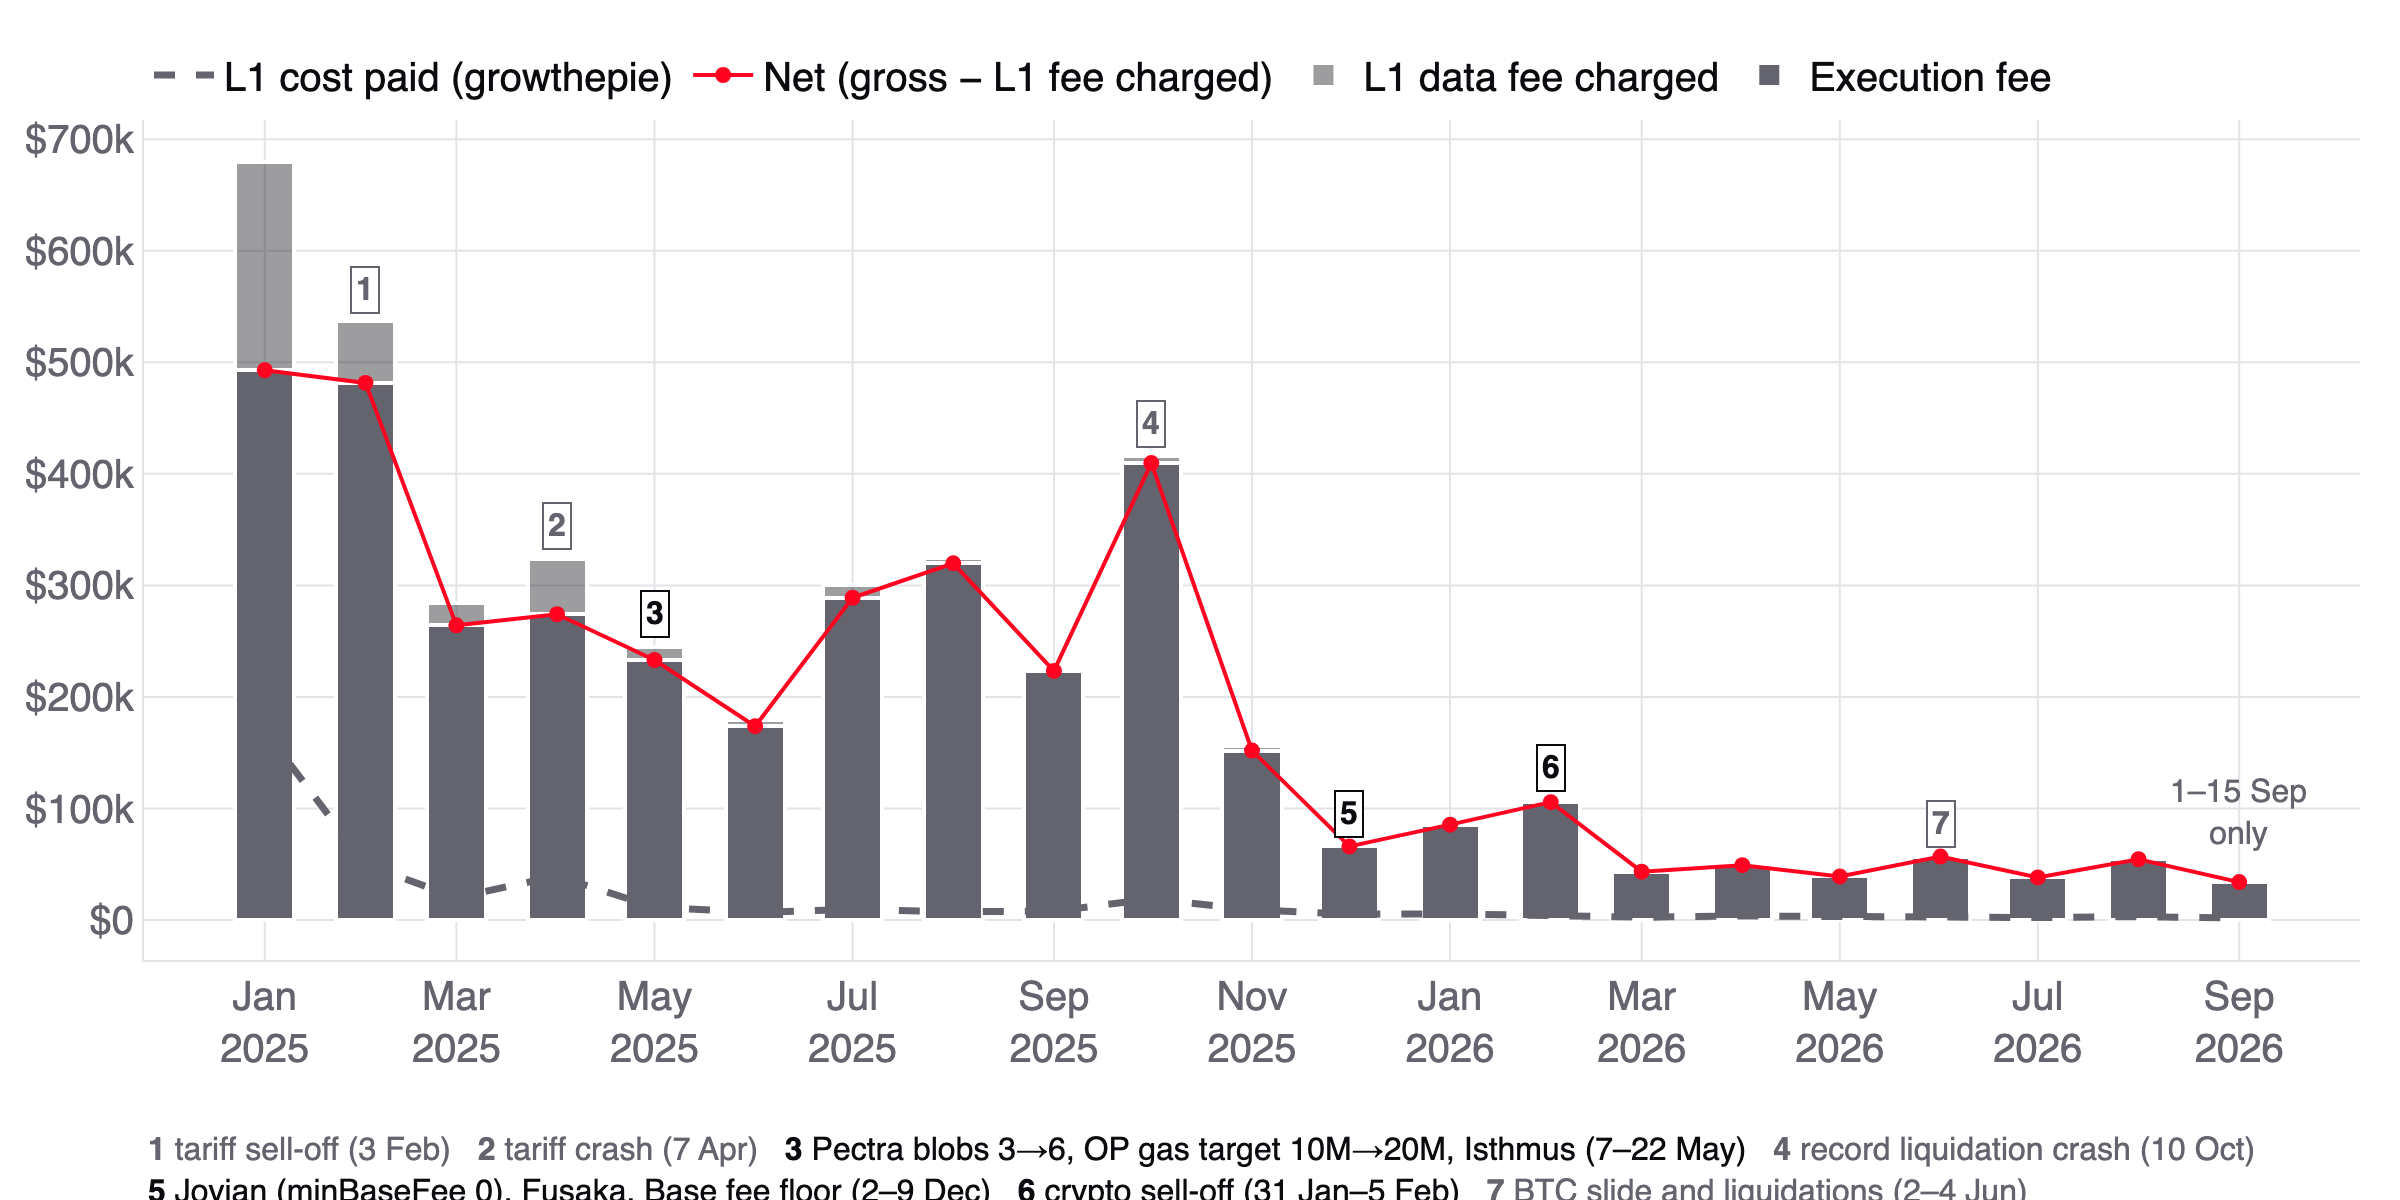

In [9]:
# one marker per month with an event: protocol months in ink, market and unexplained months in grey
MARKER_TEXT = {  # short legend text per marked month (full list: rev_events_table); no "$": two of them switch plotly to LaTeX
    "2025-02": "tariff sell-off (3 Feb)",
    "2025-04": "tariff crash (7 Apr)",
    "2025-05": "Pectra blobs 3→6, OP gas target 10M→20M, Isthmus (7–22 May)",
    "2025-10": "record liquidation crash (10 Oct)",
    "2025-12": "Jovian (minBaseFee 0), Fusaka, Base fee floor (2–9 Dec)",
    "2026-02": "crypto sell-off (31 Jan–5 Feb)",
    "2026-06": "BTC slide and liquidations (2–4 Jun)",
}
marks = []
for month, group in events_table.groupby(events_table["date"].dt.to_period("M").dt.to_timestamp()):
    kinds = set(group["kind"])
    if f"{month:%Y-%m}" in MARKER_TEXT or "data" in kinds:
        text = MARKER_TEXT.get(f"{month:%Y-%m}", f"unexplained spike ({month:%b %Y})")
        marks.append(dict(month=month, kind="protocol" if "protocol" in kinds else "market", text=text))
assert len(marks) <= 8  # the legend under the chart has room for two lines


def rev_monthly_stack(t: dict) -> go.Figure:
    fig = figure(t)
    gap = dict(color=t["bg"], width=2)
    fig.add_bar(x=monthly["month"], y=monthly["execution_fee_usd"], name="Execution fee", marker=dict(color=t["muted"], line=gap))
    fig.add_bar(x=monthly["month"], y=monthly["l1_data_fee_usd"], name="L1 data fee charged", marker=dict(color=faint(t), line=gap))
    fig.add_scatter(x=monthly["month"], y=monthly["net_usd"], name="Net (gross − L1 fee charged)",
                    mode="lines+markers", line=dict(color=t["op"], width=2), marker=dict(size=8))
    fig.add_scatter(x=monthly["month"], y=monthly["l1_cost_paid_usd"], name="L1 cost paid (growthepie)",
                    mode="lines", line=dict(color=t["muted"], width=3.5, dash="dash"))
    gross = dict(zip(monthly["month"], monthly["gross_usd"]))
    legend = []
    for i, mark in enumerate(marks, 1):
        color = t["ink"] if mark["kind"] == "protocol" else t["muted"]
        fig.add_annotation(x=mark["month"], y=gross[mark["month"]], text=f"<b>{i}</b>", showarrow=False, yshift=16,
                           font=dict(size=16, color=color), bordercolor=color, borderwidth=1, borderpad=2, bgcolor=t["bg"])
        legend.append(f"<span style='color:{color}'><b>{i}</b> {mark['text']}</span>")
    half = (len(legend) + 1) // 2
    fig.add_annotation(x=0, xref="paper", y=-0.2, yref="paper", xanchor="left", yanchor="top", align="left", showarrow=False,
                       text="   ".join(legend[:half]) + "<br>" + "   ".join(legend[half:]), font=dict(size=16))
    last = monthly.iloc[-1]
    fig.add_annotation(x=last["month"], y=last["gross_usd"], text=f"1–{last['days']} Sep<br>only", showarrow=False,
                       yshift=34, font=dict(size=16, color=t["muted"]))
    fig.update_layout(barmode="stack", bargap=0.35, margin=dict(t=60, b=120))
    fig.update_yaxes(tickprefix="$", tickformat="~s")
    fig.update_xaxes(dtick="M2", tickformat="%b<br>%Y")
    return fig


show(rev_monthly_stack)

## How much of the change in gross fees per day came from volume, fee per transaction and ETH price?

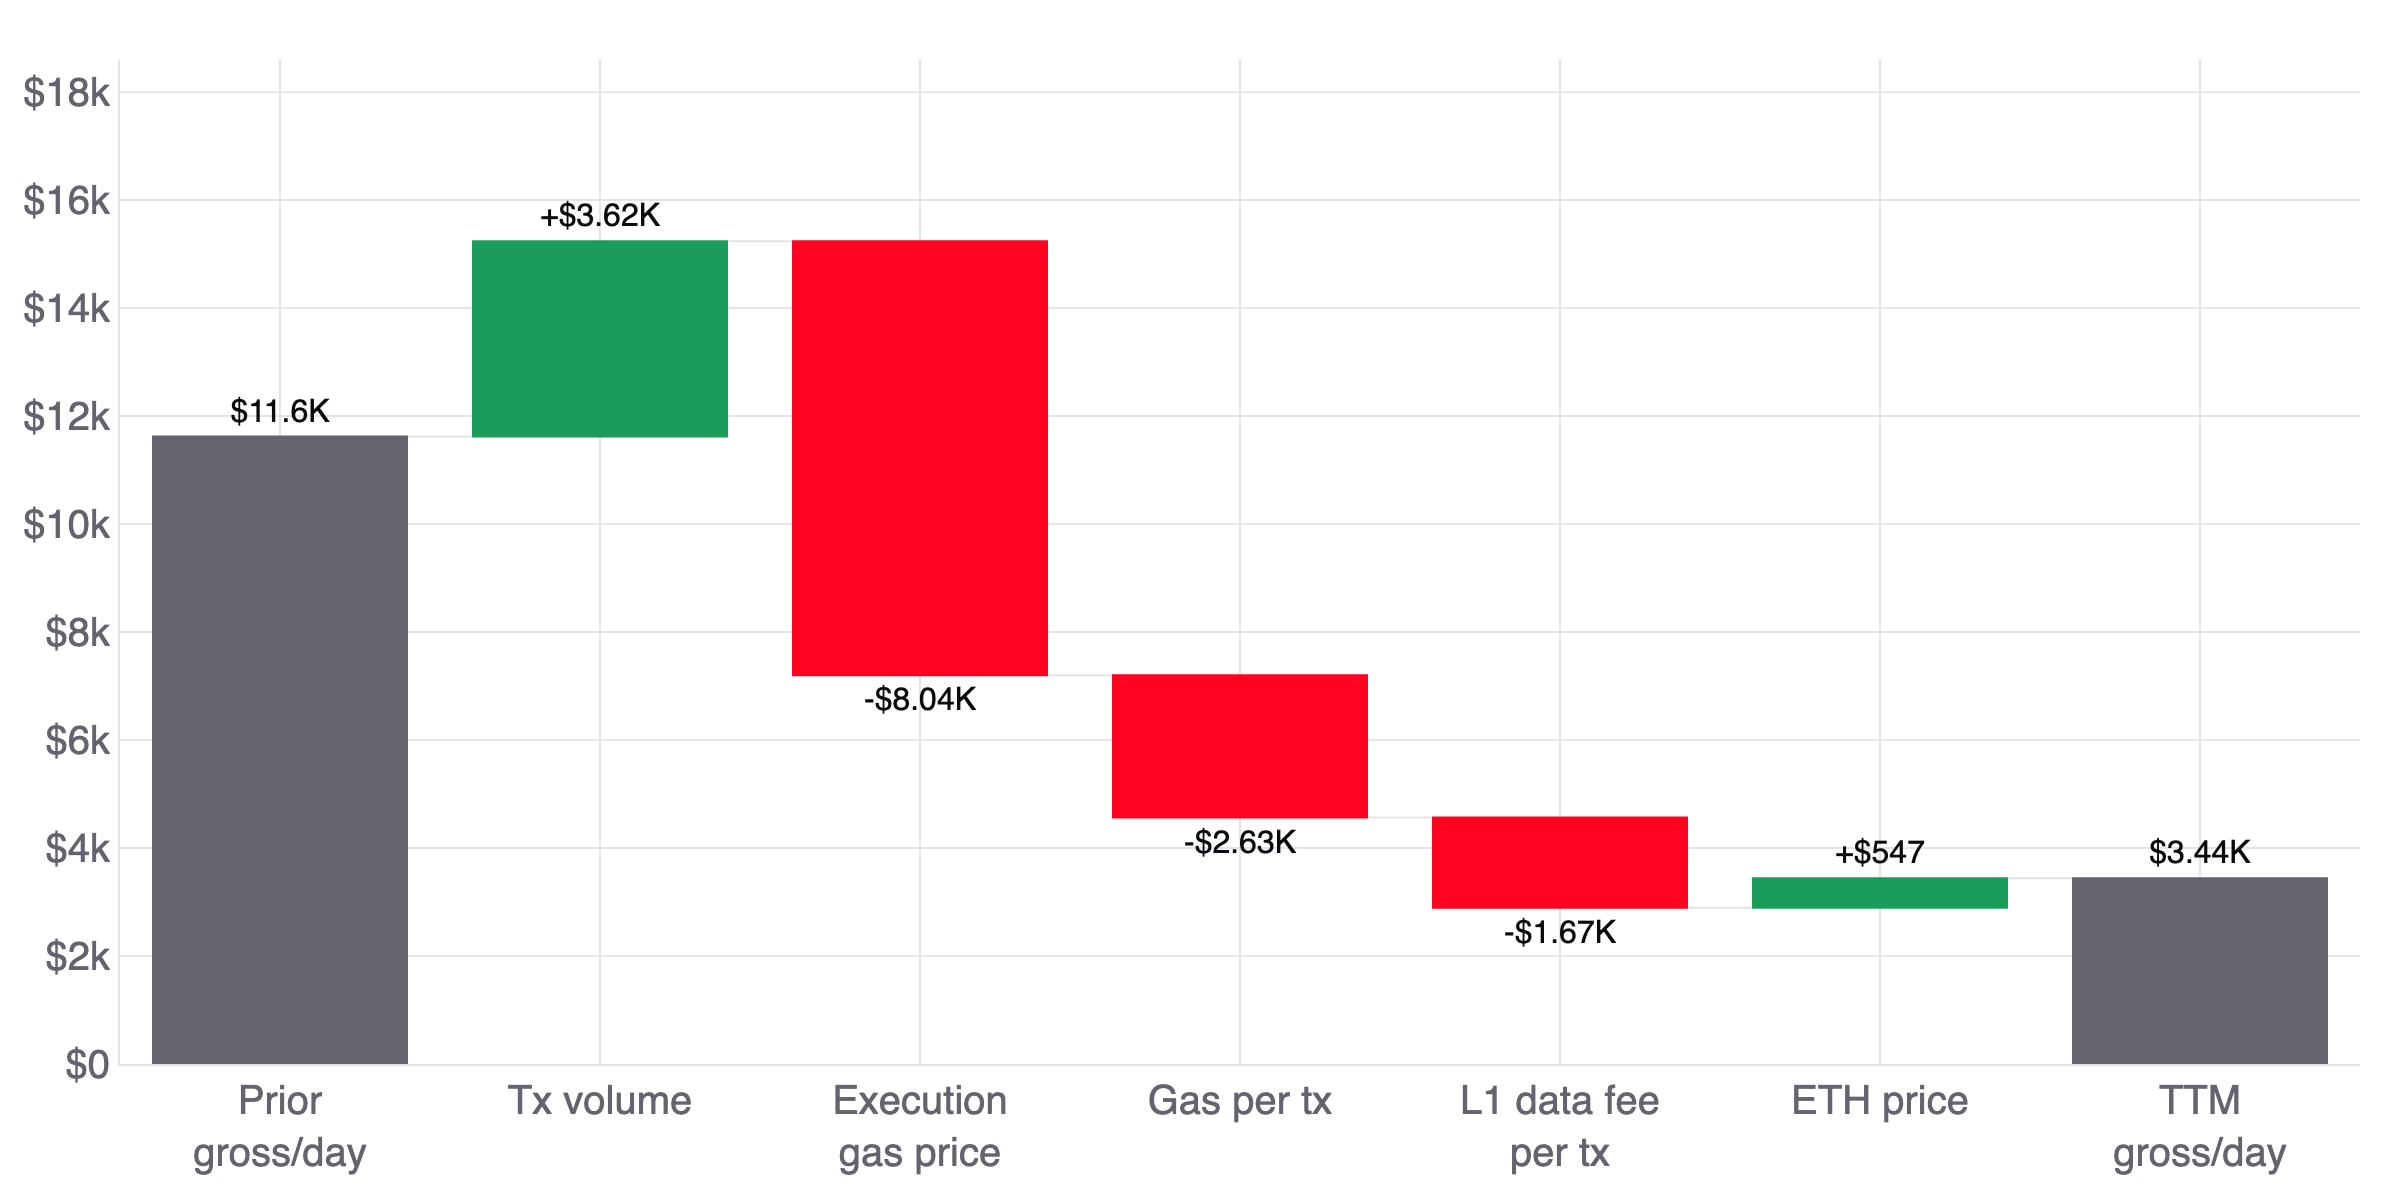

,step_no,step,measure,usd_per_day
0,1,Prior gross/day,absolute,11621.926568
1,2,Tx volume,relative,3615.093794
2,3,Execution gas price,relative,-8038.755179
3,4,Gas per tx,relative,-2633.812313
4,5,L1 data fee per tx,relative,-1670.268769
5,6,ETH price,relative,546.895916
6,7,TTM gross/day,total,3441.080017


In [10]:
# LMDI: gross/day = txs/day x fee ETH/tx x ETH price; each factor's effect = L(g1, g0) x ln(factor ratio),
# with L(a, b) = (a - b) / ln(a / b). The fee-per-tx effect is split into execution and L1 parts by their change
# in ETH/tx, and the execution part into gas price and gas per tx by their log ratios.
bridge = con.sql("""
    with p as (select * from periods where period = 'prior'),
         t as (select * from periods where period = 'ttm'),
         e as (
             select p.gross_usd_per_day as g0,
                    t.gross_usd_per_day as g1,
                    (t.gross_usd_per_day - p.gross_usd_per_day) / ln(t.gross_usd_per_day / p.gross_usd_per_day) as w,
                    ln(t.txs_per_day / p.txs_per_day) as ln_txs,
                    ln(t.fee_per_tx_eth / p.fee_per_tx_eth) as ln_fee,
                    ln(t.eth_price_usd / p.eth_price_usd) as ln_price,
                    (t.exec_fee_per_tx_eth - p.exec_fee_per_tx_eth)
                        / (t.exec_fee_per_tx_eth - p.exec_fee_per_tx_eth + t.l1_fee_per_tx_eth - p.l1_fee_per_tx_eth) as exec_part,
                    ln(t.gas_price_gwei / p.gas_price_gwei) / ln(t.exec_fee_per_tx_eth / p.exec_fee_per_tx_eth) as gas_price_part,
                    ln(t.gas_per_tx / p.gas_per_tx) / ln(t.exec_fee_per_tx_eth / p.exec_fee_per_tx_eth) as gas_per_tx_part
             from p, t
         )
    select 1 as step_no, 'Prior gross/day' as step, 'absolute' as measure, g0 as usd_per_day from e
    union all select 2, 'Tx volume', 'relative', w * ln_txs from e
    union all select 3, 'Execution gas price', 'relative', w * ln_fee * exec_part * gas_price_part from e
    union all select 4, 'Gas per tx', 'relative', w * ln_fee * exec_part * gas_per_tx_part from e
    union all select 5, 'L1 data fee per tx', 'relative', w * ln_fee * (1 - exec_part) from e
    union all select 6, 'ETH price', 'relative', w * ln_price from e
    union all select 7, 'TTM gross/day', 'total', g1 from e
    order by step_no
""").df()

note = "LMDI on prior->ttm period stats, gross USD/day"
numbers.record("rev_bridge_volume_usd_per_day", bridge["usd_per_day"][1], note=note)
numbers.record("rev_bridge_fee_per_tx_usd_per_day", bridge["usd_per_day"][2:5].sum(), note=note + "; fee ETH per tx (steps 3-5)")


def rev_bridge(t: dict) -> go.Figure:
    fig = figure(t)
    labels = [usd(v) if m != "relative" else ("+" if v > 0 else "") + usd(v) for v, m in zip(bridge["usd_per_day"], bridge["measure"])]
    fig.add_waterfall(
        x=["Prior<br>gross/day", "Tx volume", "Execution<br>gas price", "Gas per tx", "L1 data fee<br>per tx", "ETH price", "TTM<br>gross/day"],
        y=bridge["usd_per_day"], measure=bridge["measure"], text=labels, textposition="outside",
        textfont=dict(color=t["ink"], size=16), connector=dict(line=dict(color=t["line"], width=1)),
        increasing=dict(marker=dict(color=t["pos"])), decreasing=dict(marker=dict(color=t["neg"])),
        totals=dict(marker=dict(color=t["muted"])),
    )
    fig.update_layout(showlegend=False, margin=dict(t=30), bargap=0.45)
    fig.update_yaxes(tickprefix="$", tickformat="~s", range=[0, bridge["usd_per_day"][0] * 1.6])
    return fig


show(rev_bridge)
bridge

## Did the number of people using OP Mainnet grow with the transactions? (files 03, 04, 14)

Active addresses = addresses that sent at least one successful transaction that day (file 03); new addresses = first-ever senders (file 04); CEX flows = deposits plus withdrawals at centralised exchanges, in USD (file 14). These measure activity, not fees.

In [11]:
users = con.sql("""
    with cex as (select date, sum(usd_amount_in + usd_amount_out) as cex_usd from cex_flows group by date)
    select case when p.date < '2025-09-16' then 'prior' else 'ttm' end as period,
           avg(p.txs) as txs_per_day,
           avg(a.active_addresses) as active_addresses_per_day,
           avg(n.new_addresses) as new_addresses_per_day,
           sum(p.txs) / sum(a.active_addresses) as txs_per_active_address,
           avg(coalesce(c.cex_usd, 0)) as cex_flows_usd_per_day
    from pnl_daily p
    join activity a using (date)
    join new_addresses n using (date)
    left join cex c using (date)
    group by period
    order by period
""").df()
users_prior, users_ttm = users.iloc[0], users.iloc[1]

note = "files 03 (active addresses), 04 (new addresses), 14 (CEX deposits + withdrawals, USD); per day by period"
numbers.record("rev_active_addresses_prior_per_day", users_prior["active_addresses_per_day"], note=note)
numbers.record("rev_active_addresses_ttm_per_day", users_ttm["active_addresses_per_day"], note=note)
numbers.record("rev_active_addresses_change", users_ttm["active_addresses_per_day"] / users_prior["active_addresses_per_day"] - 1, note=note)
numbers.record("rev_new_addresses_change", users_ttm["new_addresses_per_day"] / users_prior["new_addresses_per_day"] - 1, note=note)
numbers.record("rev_txs_per_active_address_prior", users_prior["txs_per_active_address"], note=note + "; fee-paying txs / active addresses")
numbers.record("rev_txs_per_active_address_ttm", users_ttm["txs_per_active_address"], note=note + "; fee-paying txs / active addresses")
numbers.record("rev_cex_flows_change", users_ttm["cex_flows_usd_per_day"] / users_prior["cex_flows_usd_per_day"] - 1, note=note)
users

,period,txs_per_day,active_addresses_per_day,new_addresses_per_day,txs_per_active_address,cex_flows_usd_per_day
0,prior,1.030367e+06,92706.616279,27349.058140,11.114273,1.021469e+08
1,ttm,1.764296e+06,29718.769863,7705.750685,59.366373,5.876593e+07


## What share of transactions and execution fees went to priority bidders and high-frequency traffic?

In [12]:
payer_mix = con.sql("""
    select case when date >= '2025-09-16' then 'ttm' else 'prior' end as period,
           count(distinct date) as days,
           sum(txs) filter (where payer = 'botlike') / sum(txs) as botlike_tx_share,
           sum(fee_eth) filter (where payer = 'botlike') / count(distinct date) as botlike_fee_eth_per_day,
           sum(txs) filter (where payer = 'priority') / sum(txs) as priority_tx_share,
           sum(exec_fee_eth) filter (where payer = 'priority') / sum(exec_fee_eth) as priority_exec_share,
           sum(exec_fee_eth) filter (where payer = 'priority') / count(distinct date) as priority_exec_eth_per_day,
           sum(exec_fee_eth) / count(distinct date) as exec_eth_per_day
    from payers
    group by period
    order by period
""").df().set_index("period")
mp, mt = payer_mix.loc["prior"], payer_mix.loc["ttm"]

note = "contract_activity payer groups by period"
numbers.record("rev_botlike_fee_eth_per_day_prior", mp["botlike_fee_eth_per_day"], note=note + "; total fee ETH/day to bot-like address-days")
numbers.record("rev_botlike_fee_eth_per_day_ttm", mt["botlike_fee_eth_per_day"], note=note + "; total fee ETH/day to bot-like address-days")
numbers.record("rev_priority_tx_share_prior", mp["priority_tx_share"], note=note + "; txs to >=0.1 gwei address-days")
numbers.record("rev_priority_exec_share_prior", mp["priority_exec_share"], note=note + "; exec fee from >=0.1 gwei address-days")
numbers.record("rev_priority_exec_share_ttm", mt["priority_exec_share"], note=note + "; exec fee from >=0.1 gwei address-days")
numbers.record("rev_priority_share_of_exec_decline",
               (mp["priority_exec_eth_per_day"] - mt["priority_exec_eth_per_day"]) / (mp["exec_eth_per_day"] - mt["exec_eth_per_day"]),
               note=note + "; share of the fall in execution fee ETH/day from priority bidders")
payer_mix

,days,botlike_tx_share,botlike_fee_eth_per_day,priority_tx_share,priority_exec_share,priority_exec_eth_per_day,exec_eth_per_day
period,,,,,,,
prior,258,0.463775,0.422519,0.030450,0.728422,2.780018,3.816495
ttm,365,0.821950,0.341859,0.007431,0.471885,0.547501,1.160243


## Does the bidder result depend on the 0.1 gwei cut-off?

In [13]:
sensitivity = con.sql("""
    with thresholds(gwei) as (values (0.05::double), (0.1), (0.2), (0.5)),
    tagged as (
        select t.gwei,
               a.date,
               a.date >= '2025-09-16' as in_ttm,
               a.execution_fee_eth as exec_eth,
               a.to_address <> 'other' and a.execution_fee_eth * 1e9 >= t.gwei * a.gas_used as bidder
        from contract_activity a
        cross join thresholds t
    ), per_day as (
        select gwei,
               sum(exec_eth) filter (where bidder and not in_ttm) / count(distinct date) filter (where not in_ttm) as bidder_prior,
               sum(exec_eth) filter (where bidder and in_ttm) / count(distinct date) filter (where in_ttm) as bidder_ttm,
               sum(exec_eth) filter (where not in_ttm) / count(distinct date) filter (where not in_ttm) as all_prior,
               sum(exec_eth) filter (where in_ttm) / count(distinct date) filter (where in_ttm) as all_ttm
        from tagged
        group by gwei
    )
    select gwei,
           bidder_prior / all_prior as share_of_prior_exec_fees,
           (bidder_prior - bidder_ttm) / (all_prior - all_ttm) as share_of_exec_fee_fall
    from per_day
    order by gwei
""").df()
for row in sensitivity[sensitivity["gwei"] != 0.1].to_dict("records"):  # 0.1 gwei is the base case (rev_priority_share_of_exec_decline)
    label = f"{row['gwei']:g}".replace(".", "p")
    numbers.record(f"rev_priority_share_of_exec_decline_at_{label}gwei", row["share_of_exec_fee_fall"],
                   note=f"contract_activity; exec fee ETH/day fall from address-days >= {row['gwei']:g} gwei, prior->TTM")
sensitivity

,gwei,share_of_prior_exec_fees,share_of_exec_fee_fall
0,0.05,0.775288,0.870961
1,0.10,0.728422,0.840476
2,0.20,0.677260,0.801263
3,0.50,0.611643,0.749536


## How much did bidders pay per day, window by window?

In [14]:
steps = con.sql("""
    select case when date between '2025-01-01' and '2025-03-31' then 'q1_2025'
                when date between '2025-06-01' and '2025-08-31' then 'jun_aug_2025'
                when date between '2025-10-01' and '2025-10-31' then 'oct_2025'
                when date between '2025-12-01' and '2025-12-31' then 'dec_2025' end as window_name,
           sum(exec_fee_eth) filter (where payer = 'priority') / count(distinct date) as priority_exec_eth_per_day
    from payers
    group by window_name
    having window_name is not null
    order by min(date)
""").df()
for row in steps.to_dict("records"):
    numbers.record(f"rev_priority_exec_eth_per_day_{row['window_name']}", row["priority_exec_eth_per_day"],
                   note=f"contract_activity, {row['window_name']}; exec fee ETH/day from >=0.1 gwei address-days")
steps

,window_name,priority_exec_eth_per_day
0,q1_2025,3.995962
1,jun_aug_2025,1.642329
2,oct_2025,1.974894
3,dec_2025,0.214762


## Month by month, how did volume, fee per transaction, gas price and gas per transaction move?

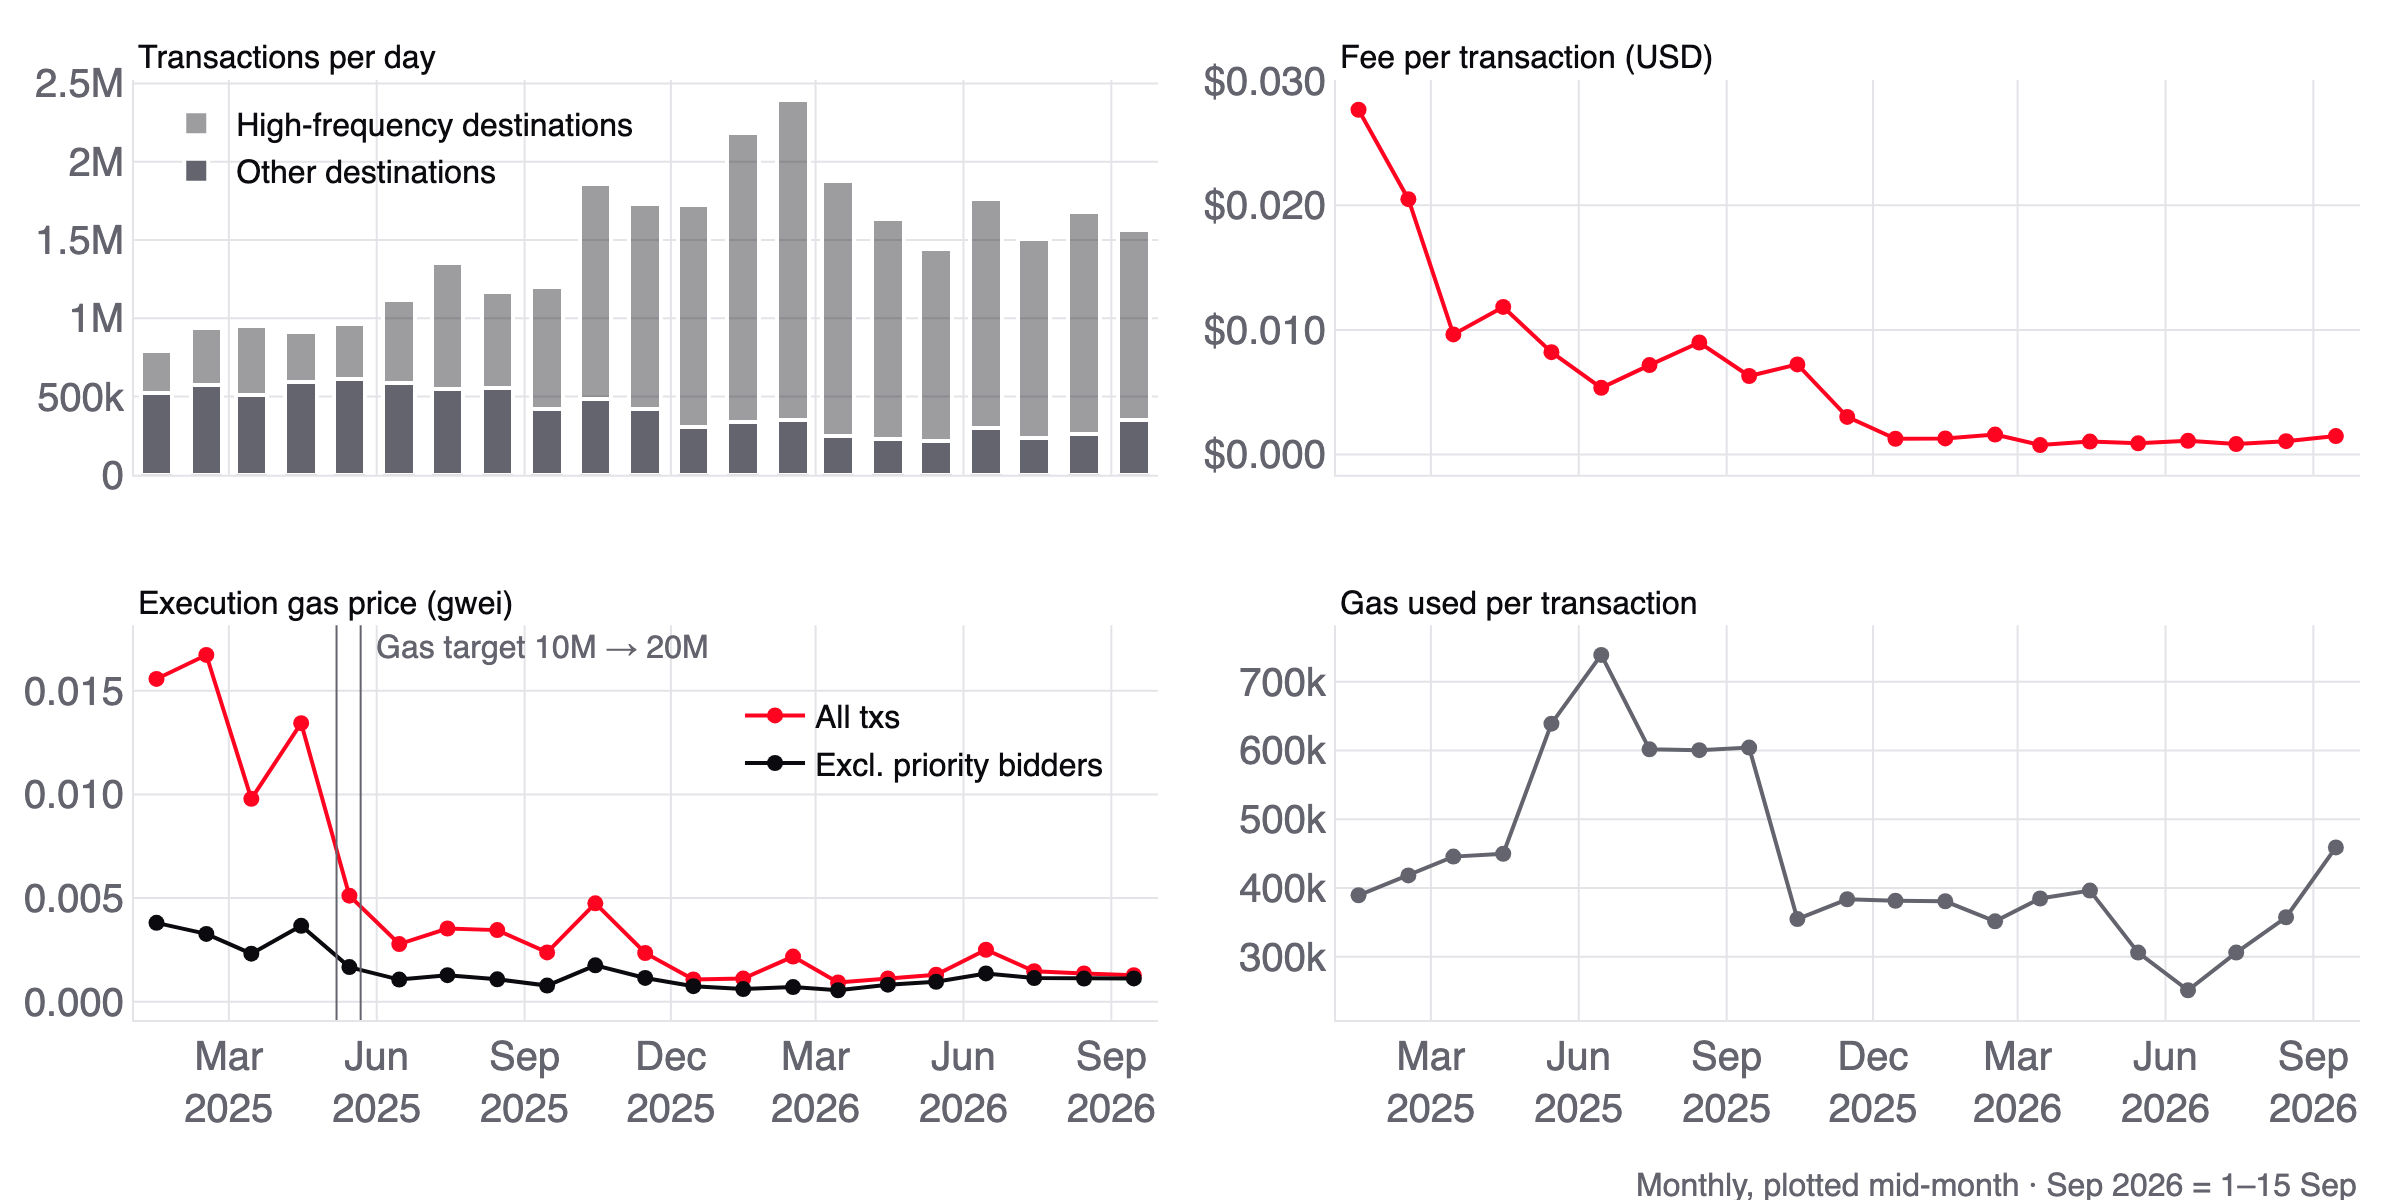

,month,txs_per_day,botlike_txs_per_day,fee_per_tx_usd,gas_price_gwei,gas_price_ex_priority_gwei,gas_per_tx
0,2025-01-01,7.920394e+05,2.711651e+05,0.027678,0.015570,0.003804,389435.314816
1,2025-02-01,9.356003e+05,3.589353e+05,0.020498,0.016729,0.003272,418279.761339
2,2025-03-01,9.522945e+05,4.446435e+05,0.009634,0.009787,0.002317,445629.067920
3,2025-04-01,9.114764e+05,3.195974e+05,0.011840,0.013437,0.003662,449844.144744
4,2025-05-01,9.631753e+05,3.520991e+05,0.008207,0.005115,0.001670,638940.995850
5,2025-06-01,1.119792e+06,5.302655e+05,0.005346,0.002782,0.001067,738866.229186
6,2025-07-01,1.352703e+06,8.058995e+05,0.007170,0.003532,0.001282,601644.581401
7,2025-08-01,1.165346e+06,6.100741e+05,0.008986,0.003453,0.001078,600354.524970
8,2025-09-01,1.202978e+06,7.804939e+05,0.006294,0.002377,0.000778,604101.985808
9,2025-10-01,1.855666e+06,1.371768e+06,0.007227,0.004746,0.001756,354805.204604


In [15]:
fee_mix = con.sql("""
    with m as (
        select date,
               sum(txs) filter (where payer = 'botlike') as botlike_txs,
               sum(exec_fee_eth) filter (where payer <> 'priority') as exec_eth_ex_priority,
               sum(gas_used) filter (where payer <> 'priority') as gas_ex_priority
        from payers
        group by date
    )
    select date_trunc('month', p.date)::date as month,
           sum(p.txs) / count(*) as txs_per_day,
           coalesce(sum(m.botlike_txs), 0) / count(*) as botlike_txs_per_day,
           sum(p.gross_fee_usd) / sum(p.txs) as fee_per_tx_usd,
           sum(p.execution_fee_eth) * 1e9 / sum(p.gas_used) as gas_price_gwei,
           sum(m.exec_eth_ex_priority) * 1e9 / sum(m.gas_ex_priority) as gas_price_ex_priority_gwei,
           sum(p.gas_used) / sum(p.txs) as gas_per_tx
    from pnl_daily p
    join m using (date)
    group by month
    order by month
""").df()
GAS_TARGET_CHANGES = ("2025-05-07", "2025-05-22")


def rev_fee_per_tx(t: dict) -> go.Figure:
    fig = subplots(t, rows=2, cols=2, shared_xaxes=True, vertical_spacing=0.16, horizontal_spacing=0.08,
                   subplot_titles=("Transactions per day", "Fee per transaction (USD)",
                                   "Execution gas price (gwei)", "Gas used per transaction"))
    x = fee_mix["month"] + timedelta(days=14)  # plot monthly values mid-month; event lines are day-exact
    gap = dict(color=t["bg"], width=2)
    fig.add_bar(x=x, y=fee_mix["txs_per_day"] - fee_mix["botlike_txs_per_day"], name="Other destinations",
                marker=dict(color=t["muted"], line=gap), legend="legend", row=1, col=1)
    fig.add_bar(x=x, y=fee_mix["botlike_txs_per_day"], name="High-frequency destinations",
                marker=dict(color=faint(t), line=gap), legend="legend", row=1, col=1)
    fig.add_scatter(x=x, y=fee_mix["fee_per_tx_usd"], mode="lines+markers", showlegend=False,
                    line=dict(color=t["op"], width=2), marker=dict(size=8), row=1, col=2)
    fig.add_scatter(x=x, y=fee_mix["gas_price_gwei"], mode="lines+markers", name="All txs",
                    line=dict(color=t["op"], width=2), marker=dict(size=8), legend="legend2", row=2, col=1)
    fig.add_scatter(x=x, y=fee_mix["gas_price_ex_priority_gwei"], mode="lines+markers",
                    name="Excl. priority bidders", line=dict(color=t["ink"], width=2), marker=dict(size=8),
                    legend="legend2", row=2, col=1)
    fig.add_scatter(x=x, y=fee_mix["gas_per_tx"], mode="lines+markers", showlegend=False,
                    line=dict(color=t["muted"], width=2), marker=dict(size=8), row=2, col=2)
    for day in GAS_TARGET_CHANGES:
        fig.add_vline(x=day, line=dict(color=t["muted"], width=1), row=2, col=1)
    fig.add_annotation(x=GAS_TARGET_CHANGES[1], y=1, yref="y3 domain", text="Gas target 10M → 20M", xref="x3", xanchor="left",
                       xshift=6, showarrow=False, font=dict(size=16, color=t["muted"]))
    fig.add_annotation(x=1, xref="paper", y=-0.2, yref="paper", xanchor="right", showarrow=False,
                       text="Monthly, plotted mid-month · Sep 2026 = 1–15 Sep", font=dict(size=16, color=t["muted"]))
    inner = dict(orientation="v", xanchor="left", yanchor="top", bgcolor="rgba(0,0,0,0)", font=dict(size=16))
    fig.update_layout(barmode="stack", bargap=0.3, margin=dict(t=40, b=90),
                      legend=dict(inner, x=0.01, y=0.99, traceorder="reversed"), legend2=dict(inner, x=0.27, y=0.36))
    fig.update_yaxes(tickformat="~s")
    fig.update_yaxes(tickprefix="$", tickformat=".3f", row=1, col=2)
    fig.update_yaxes(tickformat=".3f", row=2, col=1)
    fig.update_xaxes(dtick="M3", tick0="2025-03-01", tickformat="%b<br>%Y", range=["2025-01-01", "2026-09-30"])
    return fig


show(rev_fee_per_tx)
fee_mix

## Who were the biggest bidders in the prior period? (Wintermute = Allium `entity_project`)

In [16]:
bidders = con.sql("""
    with t as (
        select *,
               execution_fee_eth * 1e9 >= 0.1 * gas_used as bidder,  -- priority bidder that day
               date >= '2025-09-16' as in_ttm
        from contract_activity
        where to_address <> 'other'
    ), all_prior as (
        select sum(execution_fee_eth) as exec_eth from contract_activity where date < '2025-09-16'
    )
    select t.to_address as address, c.app, c.segment, l.entity_project, l.display_name,
           count(*) filter (where bidder and not in_ttm) as tagged_days_prior,
           coalesce(sum(execution_fee_eth) filter (where bidder and not in_ttm), 0) as bidder_exec_eth_prior,
           coalesce(sum(execution_fee_eth) filter (where not in_ttm), 0) as exec_eth_prior,
           coalesce(sum(execution_fee_eth) filter (where bidder and not in_ttm), 0) / any_value(ap.exec_eth) as share_of_prior_exec,
           coalesce(sum(execution_fee_eth) filter (where in_ttm), 0) as exec_eth_ttm,
           median(distinct_senders) as median_daily_senders,
           c.app not like 'unlabeled-%' as named
    from t
    left join m_customer_app c on c.address = t.to_address
    left join labels l on l.address = t.to_address
    cross join all_prior ap
    group by all
    having count(*) filter (where bidder and not in_ttm) > 0
    order by bidder_exec_eth_prior desc
""").df()
BIDDER_MIN_DAYS = 30
top_bidders = bidders.head(10)
numbers.record("rev_priority_bidder_table", [
    dict(address=r["address"], name=r["app"], display_name=r["display_name"], entity_project=r["entity_project"],
         segment=r["segment"], tagged_days_prior=r["tagged_days_prior"], bidder_exec_eth_prior=r["bidder_exec_eth_prior"],
         exec_eth_prior=r["exec_eth_prior"], share_of_prior_exec=r["share_of_prior_exec"], exec_eth_ttm=r["exec_eth_ttm"],
         median_daily_senders=r["median_daily_senders"])
    for r in top_bidders.astype(object).where(top_bidders.notna(), None).to_dict("records")  # missing labels -> null
], note="contract_activity x m_customer_app x labels; top 10 destinations by prior-period exec fee on >=0.1 gwei days; share = that / all prior exec fee")
numbers.record("rev_priority_bidder_named_share_prior",
               bidders.loc[bidders["named"], "bidder_exec_eth_prior"].sum() / bidders["bidder_exec_eth_prior"].sum(),
               note="prior exec fee on >=0.1 gwei destination-days going to named apps (m_customer_app.app not 'unlabeled-*') / all such fee")
numbers.record("rev_priority_bidder_count_prior", (bidders["tagged_days_prior"] >= BIDDER_MIN_DAYS).sum(),
               note=f"distinct destinations tagged priority bidder on >= {BIDDER_MIN_DAYS} prior-period days")
top_bidders.drop(columns="named")

,address,app,segment,entity_project,display_name,tagged_days_prior,bidder_exec_eth_prior,exec_eth_prior,share_of_prior_exec,exec_eth_ttm,median_daily_senders
0,0x62d2293e1db885e8ba8eeac7829a7eae26cee15a,wintermute,bots_automation,wintermute,Wintermute,191,213.674917,213.674917,0.217005,0.000000,22.0
1,0x6f1fe5b048de0417c4e838b1fc4245aaf254f1dc,wintermute,bots_automation,wintermute,Wintermute,65,139.783623,139.783623,0.141962,0.000000,22.0
2,0x9d603a45321a3adbfcad0e49fd944cc281baa833,unlabeled-9d603a45321a3adbfcad0e49fd944cc281ba...,bots_automation,NaN,StrategyExecutor,131,29.672970,29.672970,0.030135,0.000000,2.0
3,0x1dc68046e71429f646dd6b2d0c02385ae61c2129,unlabeled-1dc680,bots_automation,NaN,Order Manager,63,28.993164,28.993164,0.029445,7.222244,2.0
4,0x94b008aa00579c1307b0ef2c499ad98a8ce58e58,tether,stablecoin_payments,tether,Tether: USDT,92,22.831664,32.917270,0.023187,12.395281,5600.0
5,0x0800af460a1b8c8daf01f756de8d9d0a58106701,unlabeled-0800af,bots_automation,NaN,StrategyExecutor,211,18.075303,19.234022,0.018357,1.797086,1.0
6,0xeb4378aacdfb7d02a0c9accfac2e90ad545ad62a,unlabeled-eb4378,bots_automation,NaN,StrategyExecutor,139,10.956604,14.200058,0.011127,4.327167,1.0
7,0x3f220661e77f9fb98a4e32745d02fbae6b25038b,unlabeled-3f220661e77f9fb98a4e32745d02fbae6b25...,unlabeled,NaN,NaN,12,10.146928,10.146928,0.010305,0.000000,1.0
8,0x38edf0a0d32b5c8e23284da87d078062a3f772a7,unlabeled-38edf0a0d32b5c8e23284da87d078062a3f7...,bridge_messaging,NaN,Router,64,10.105376,13.208527,0.010263,0.556296,2.0
9,0xd55267afff150a456ba41553eeac9dac635f05d6,unlabeled-d55267,bots_automation,NaN,StrategyExecutor,205,9.222225,9.222225,0.009366,2.314545,1.0


## Wintermute: did it leave, or just pay less?

Wintermute = Allium `entity_project = wintermute` on two contracts. A third, unlabelled contract (`0x1ef354…`) is attributed to it **by inference**: it starts on the day the second labelled contract stops, with the same footprint.

In [17]:
WINTERMUTE_SUCCESSOR = "0x1ef354f86058c1f4af8b8b1f3ff0c2fc31d539e9"  # inferred
footprint = con.sql(f"""
    with family as (
        select address, coalesce(display_name, 'unlabelled') as name, deployed_date
        from labels
        where entity_project = 'wintermute' or address = '{WINTERMUTE_SUCCESSOR}'
    ), handover as (  -- last day of Wintermute's labelled contracts
        select max(a.date) as day
        from contract_activity a join labels l on l.address = a.to_address
        where l.entity_project = 'wintermute'
    ), spans as (
        select to_address, min(date) as first_day, max(date) as last_day from contract_activity group by to_address
    )
    select f.address, f.name, f.deployed_date, s.first_day, s.last_day,
           median(a.distinct_senders) filter (where a.txs >= 1000) as median_daily_senders,
           max(a.distinct_senders) filter (where a.date = h.day) as senders_on_handover_day,
           median(a.execution_fee_eth * 1e9 / a.gas_used) filter (where a.date < s.first_day + 30) as gwei_median_first_30d,
           median(a.execution_fee_eth * 1e9 / a.gas_used) filter (where a.date > s.last_day - 30) as gwei_median_last_30d,
           sum(a.gas_used) / sum(a.txs) as gas_per_tx,
           sum(a.execution_fee_eth) filter (where a.date < '2025-09-16') as exec_eth_prior,
           sum(a.execution_fee_eth) filter (where a.date >= '2025-09-16') as exec_eth_ttm
    from family f
    join contract_activity a on a.to_address = f.address
    join spans s on s.to_address = f.address
    cross join handover h
    group by all
    order by s.first_day
""").df()
labelled = footprint[footprint["name"] == "Wintermute"]
handover_day = labelled["last_day"].max()
old_contract = labelled.loc[labelled["last_day"] == handover_day, "address"].item()
handover_gas_per_tx = dict(con.sql(f"""
    select to_address, gas_used / txs from contract_activity
    where date = '{handover_day:%Y-%m-%d}' and to_address in ('{old_contract}', '{WINTERMUTE_SUCCESSOR}')
""").fetchall())
prior_exec_eth = con.sql("select sum(execution_fee_eth) from contract_activity where date < '2025-09-16'").fetchone()[0]

note = "contract_activity x labels entity_project='wintermute'"
numbers.record("rev_wintermute_prior_exec_share", labelled["exec_eth_prior"].sum() / prior_exec_eth,
               note=note + ", prior; exec fee of txs sent to them / all exec fee (file 06)")
numbers.record("rev_wintermute_migration_day", f"{handover_day:%Y-%m-%d}",
               note="last day of Wintermute's labelled contract = first full day of the unlabelled successor (file 06)")
numbers.record("rev_wintermute_handover_gas_per_tx_old", handover_gas_per_tx[old_contract],
               note="contract_activity gas/tx on the handover day, Wintermute's labelled contract")
numbers.record("rev_wintermute_handover_gas_per_tx_new", handover_gas_per_tx[WINTERMUTE_SUCCESSOR],
               note="contract_activity gas/tx on the handover day, unlabelled successor")
footprint

,address,name,deployed_date,first_day,last_day,median_daily_senders,senders_on_handover_day,gwei_median_first_30d,gwei_median_last_30d,gas_per_tx,exec_eth_prior,exec_eth_ttm
0,0x6f1fe5b048de0417c4e838b1fc4245aaf254f1dc,Wintermute,2024-10-04,2025-01-01,2025-03-06,22.0,<NA>,1.479579,1.280098,186248.152216,139.783623,NaN
1,0x62d2293e1db885e8ba8eeac7829a7eae26cee15a,Wintermute,2025-03-04,2025-03-06,2025-09-12,22.0,15,1.150322,0.470968,186086.625788,213.674917,NaN
2,0x1ef354f86058c1f4af8b8b1f3ff0c2fc31d539e9,unlabelled,2025-09-08,2025-09-11,2026-09-15,16.0,15,0.183517,0.005080,150170.377841,1.568373,52.748873


## One row per Wintermute contract: did they leave, or just pay less per transaction?

In [18]:
wm_contracts = con.sql(f"""
    select a.to_address as address,
           case when any_value(l.entity_project) = 'wintermute' then 'Allium entity_project = wintermute'
                else 'inferred successor (unlabelled)' end as identified_by,
           strftime(any_value(l.deployed_date), '%Y-%m-%d') as deployed_date,
           strftime(min(a.date), '%Y-%m-%d') as first_active,
           strftime(max(a.date), '%Y-%m-%d') as last_active,
           count(*) as active_days,
           coalesce(sum(a.execution_fee_eth) filter (where a.date < '2025-09-16'), 0) as exec_eth_prior,
           coalesce(sum(a.execution_fee_eth) filter (where a.date >= '2025-09-16'), 0) as exec_eth_ttm,
           sum(a.txs) / count(*) as txs_per_active_day,
           sum(a.gas_used) / sum(a.txs) as gas_per_tx,
           median(a.execution_fee_eth * 1e9 / a.gas_used) as median_effective_gwei
    from contract_activity a
    join labels l on l.address = a.to_address
    where l.entity_project = 'wintermute' or a.to_address = '{WINTERMUTE_SUCCESSOR}'
    group by a.to_address
    order by first_active
""").df()
numbers.record("rev_wintermute_contracts_table", wm_contracts.to_dict("records"),
               note="contract_activity x labels; the two entity_project='wintermute' contracts + inferred successor 0x1ef354; txs/day per active day")
wm_contracts

,address,identified_by,deployed_date,first_active,last_active,active_days,exec_eth_prior,exec_eth_ttm,txs_per_active_day,gas_per_tx,median_effective_gwei
0,0x6f1fe5b048de0417c4e838b1fc4245aaf254f1dc,Allium entity_project = wintermute,2024-10-04,2025-01-01,2025-03-06,65,139.783623,0.000000,6972.784615,186248.152216,1.382603
1,0x62d2293e1db885e8ba8eeac7829a7eae26cee15a,Allium entity_project = wintermute,2025-03-04,2025-03-06,2025-09-12,191,213.674917,0.000000,5111.869110,186086.625788,1.239962
2,0x1ef354f86058c1f4af8b8b1f3ff0c2fc31d539e9,inferred successor (unlabelled),2025-09-08,2025-09-11,2026-09-15,370,1.568373,52.748873,16853.035135,150170.377841,0.006200


## What lines up with the two late-2025 steps in bidder tips? (files 06, 09, 14)

For every day in November and December 2025, the median of the 14 days from that day is compared with the 14 days before it; the day with the largest fall in bidder tips in each month is that month's step. At the same split: transactions sent to Wintermute's inferred contract, DEX volume (file 09) and CEX deposits plus withdrawals (file 14). Moving together is consistent with a trading slowdown, not proof of one.

In [19]:
tip_steps = con.sql(f"""
    with daily as (
        select p.date,
               sum(p.exec_fee_eth) filter (where p.payer = 'priority') as tips_eth,
               any_value(w.txs) as wintermute_txs,
               any_value(c.cex_usd) as cex_usd,
               any_value(x.dex_usd) as dex_usd
        from payers p
        left join (select date, txs from contract_activity where to_address = '{WINTERMUTE_SUCCESSOR}') w using (date)
        left join (select date, sum(usd_amount_in + usd_amount_out) as cex_usd from cex_flows group by date) c using (date)
        left join (select date, sum(total_volume_usd) as dex_usd from dex_volume group by date) x using (date)
        group by p.date
    ), windows as (
        select date,
               median(tips_eth) over before_w as tips_before, median(tips_eth) over after_w as tips_after,
               median(wintermute_txs) over after_w / median(wintermute_txs) over before_w - 1 as wintermute_txs_change,
               median(dex_usd) over after_w / median(dex_usd) over before_w - 1 as dex_volume_change,
               median(cex_usd) over after_w / median(cex_usd) over before_w - 1 as cex_flows_change
        from daily
        window before_w as (order by date rows between 14 preceding and 1 preceding),
               after_w as (order by date rows between current row and 13 following)
    )
    select date as step_day, tips_before, tips_after, tips_after / tips_before - 1 as tips_change,
           wintermute_txs_change, dex_volume_change, cex_flows_change
    from windows
    where date between '2025-11-01' and '2025-12-31'
    qualify row_number() over (partition by month(date) order by tips_after / tips_before) = 1
    order by date
""").df()

note = "payers (>= 0.1 gwei destination-days), contract_activity, files 09 and 14; median of 14 days from the step day / 14 days before - 1"
for i, row in enumerate(tip_steps.to_dict("records"), 1):
    numbers.record(f"rev_tip_step{i}_day", f"{row['step_day']:%Y-%m-%d}", note="day of the largest 14-day fall in bidder tips, " + ("November" if i == 1 else "December") + " 2025")
    for col in ("tips_change", "wintermute_txs_change", "dex_volume_change", "cex_flows_change"):
        numbers.record(f"rev_tip_step{i}_{col}", row[col], note=note)
tip_steps

,step_day,tips_before,tips_after,tips_change,wintermute_txs_change,dex_volume_change,cex_flows_change
0,2025-11-26,0.264098,0.146774,-0.444246,-0.410047,-0.353245,-0.435241
1,2025-12-21,0.222304,0.113921,-0.487541,-0.530953,-0.371470,0.035210


## Why did the execution gas price fall? Gas target and base fee from block headers

OP Mainnet's EIP-1559 base fee rises when blocks use more than the gas target (gas limit / elasticity) and decays towards its floor when they use less ([gas target docs](https://docs.optimism.io/chain-operators/guides/management/gas-target-limit)). Since Holocene the limit and elasticity are in every block header ([Holocene spec](https://specs.optimism.io/protocol/holocene/exec-engine.html)). `data/external/op_block_headers.csv` samples one header every 6 hours from the public RPC (`uv run python -m src.pull_block_headers`). Before Holocene (9 Jan 2025) elasticity was the constant 6. File 06 usage excludes deposit transactions, so it slightly understates block fullness; the headers' own `gas_used` is shown alongside.

| Block | UTC | Gas limit | Elasticity | Gas target | What changed |
|---|---|---|---|---|---|
| [130423412](https://optimistic.etherscan.io/block/130423412) | 2025-01-09 18:00 | 60M | 6 | 10M | Holocene: EIP-1559 params move into the header (values unchanged) |
| [135513415](https://optimistic.etherscan.io/block/135513415) | 2025-05-07 13:46 | 60M | 4 | 15M | elasticity 6 → 4 |
| [136165875](https://optimistic.etherscan.io/block/136165875) | 2025-05-22 16:15 | 40M | 2 | 20M | gas limit 60M → 40M, elasticity 4 → 2 |
| [144546212](https://optimistic.etherscan.io/block/144546212) | 2025-12-02 16:00 | 40M | 2 | 20M | Jovian: adds a `minBaseFee` header field, set to **0** (no floor) |

In [20]:
regimes = con.sql("""
    with samples as (
        select *, gas_limit / coalesce(eip1559_elasticity, 6) as gas_target from op_block_headers  -- 6 = pre-Holocene elasticity
    ), daily_target as (
        select date, arg_max(gas_target, timestamp_utc) as gas_target from samples group by date
    ), header_stats as (
        select t.gas_target, s.date >= '2025-09-16' as in_ttm, count(*) as header_samples,
               avg(s.gas_used) as header_gas_per_block,
               quantile_cont(s.base_fee_wei, 0.5) as base_fee_p50_wei,
               quantile_cont(s.base_fee_wei, 0.9) as base_fee_p90_wei,
               avg((s.base_fee_wei >= 100000)::int) as share_base_fee_over_0p0001_gwei
        from samples s join daily_target t using (date)
        group by all
    ), usage as (
        select t.gas_target, d.date >= '2025-09-16' as in_ttm, min(d.date) as first_day, max(d.date) as last_day,
               sum(d.gas_used) / (count(*) * 43200) as gas_per_block,  -- 43,200 two-second blocks a day
               sum(d.execution_fee_eth) * 1e9 / sum(d.gas_used) as gas_price_gwei
        from pnl_daily d join daily_target t using (date)
        group by all
    )
    select first_day, last_day, gas_target, gas_per_block, gas_per_block / gas_target as target_utilisation,
           header_gas_per_block, header_gas_per_block / gas_target as header_target_utilisation, gas_price_gwei,
           header_samples, base_fee_p50_wei, base_fee_p90_wei, share_base_fee_over_0p0001_gwei
    from usage
    join header_stats using (gas_target, in_ttm)
    order by first_day
""").df()
median_base_fee_prior_wei = con.sql("select median(base_fee_wei) from op_block_headers where date < '2025-09-16'").fetchone()[0]
before, after = regimes.iloc[0], regimes.iloc[-1]

note = "pnl_daily gas_used / (days x 43,200 blocks) vs header gas target"
numbers.record("rev_gas_target_before", before["gas_target"], note="op_block_headers: 60M limit / elasticity 6")
numbers.record("rev_gas_target_after", after["gas_target"], note="op_block_headers from 2025-05-22: 40M limit / elasticity 2")
numbers.record("rev_target_utilisation_before", before["target_utilisation"], note=note + ", 1 Jan-6 May 2025")
numbers.record("rev_target_utilisation_ttm", after["target_utilisation"], note=note + ", TTM")
numbers.record("rev_median_base_fee_share_of_gas_price", median_base_fee_prior_wei / (prior["gas_price_gwei"] * 1e9),
               note="op_block_headers median base fee (prior samples) / prior effective execution gas price")
numbers.record("rev_min_base_fee_wei", latest_min_base_fee, note="op_block_headers, minBaseFee in the latest sampled header (Jovian field)")
regimes

,first_day,last_day,gas_target,gas_per_block,target_utilisation,header_gas_per_block,header_target_utilisation,gas_price_gwei,header_samples,base_fee_p50_wei,base_fee_p90_wei,share_base_fee_over_0p0001_gwei
0,2025-01-01,2025-05-06,10000000.0,8.890091e+06,0.889009,9.043339e+06,0.904334,0.013197,504,4692.5,1141748.6,0.365079
1,2025-05-07,2025-05-21,15000000.0,1.445493e+07,0.963662,1.535426e+07,1.023618,0.006101,60,20064.5,37200.2,0.033333
2,2025-05-22,2025-09-15,20000000.0,1.778185e+07,0.889093,1.652436e+07,0.826218,0.003215,468,1124.5,10190.8,0.023504
3,2025-09-16,2026-09-15,20000000.0,1.480483e+07,0.740242,1.448379e+07,0.724190,0.001814,1460,496.0,5163.2,0.022603


## Did anything else change on the day of the first gas-target change? (file 05)

Contracts deployed per day (including contracts created by other contracts) and distinct deployers, in the 14 days before 7 May 2025 and from 7 to 20 May, between the two target changes.

In [21]:
deployments_at_target_change = con.sql("""
    select case when date < '2025-05-07' then 'before' else 'after' end as window_name,
           min(date) as first_day, max(date) as last_day,
           avg(new_deployed_contracts) as contracts_deployed_per_day,
           avg(distinct_contract_deployers) as deployers_per_day
    from deployments
    where date between '2025-04-23' and '2025-05-20'
    group by window_name
    order by first_day
""").df()
target_before, target_after = deployments_at_target_change.iloc[0], deployments_at_target_change.iloc[1]

note = "file 05, 23 Apr-6 May vs 7-20 May 2025 (gas target 10M -> 15M on 7 May)"
numbers.record("rev_deployments_per_day_before_target_change", target_before["contracts_deployed_per_day"], note=note)
numbers.record("rev_deployments_per_day_after_target_change", target_after["contracts_deployed_per_day"], note=note)
numbers.record("rev_deployers_change_at_target_change", target_after["deployers_per_day"] / target_before["deployers_per_day"] - 1, note=note)
deployments_at_target_change

,window_name,first_day,last_day,contracts_deployed_per_day,deployers_per_day
0,before,2025-04-23,2025-05-06,75903.285714,910.928571
1,after,2025-05-07,2025-05-20,513452.357143,1122.071429


## How much did apps earn, and what was our take of it?

In [22]:
apps = con.sql("""
    with op as (
        select case when date >= '2025-09-16' then 'ttm' else 'prior' end as period,
               count(*) as days, sum(net_fee_usd) as op_net_usd
        from pnl_daily
        group by period
    ), app as (
        select case when date >= '2025-09-16' then 'ttm' else 'prior' end as period,
               count(distinct date) as days,
               sum(fee_usd) as app_fees_usd,
               sum(revenue_usd) as app_revenue_usd,
               sum(fee_usd) filter (where revenue_usd is null) / sum(fee_usd) as fees_without_revenue_share
        from app_fees
        where date <= '2026-09-15'
        group by period
    )
    select period, op.op_net_usd, app.app_fees_usd, app.app_revenue_usd, app.fees_without_revenue_share,
           app.app_fees_usd / app.days as app_fees_usd_per_day,
           (op.op_net_usd / op.days) / (app.app_fees_usd / app.days) as take_of_app_fees,
           op.op_net_usd / app.app_revenue_usd as take_of_app_revenue
    from op join app using (period)
    order by period
""").df().set_index("period")
ap, at = apps.loc["prior"], apps.loc["ttm"]

note = "app_fees (file 08), TTM window"
numbers.record("rev_ttm_app_fees_usd", at["app_fees_usd"], note=note)
numbers.record("rev_ttm_app_revenue_usd", at["app_revenue_usd"], note=note + "; revenue_usd null rows count as 0")
numbers.record("rev_take_rate_on_app_fees", at["take_of_app_fees"], note="TTM OP net USD (internal basis) / TTM app fees")
numbers.record("rev_app_revenue_vs_net_multiple", 1 / at["take_of_app_revenue"], note="TTM app revenue / TTM OP net USD (internal basis)")
numbers.record("rev_take_rate_on_app_revenue", at["take_of_app_revenue"],
               note="TTM OP net USD (internal basis) / TTM app revenue; upper bound (revenue missing for 7.3% of TTM app fees)")
numbers.record("rev_take_rate_on_app_fees_prior", ap["take_of_app_fees"], note="prior OP net USD/day (internal basis) / prior app fees USD/day")
numbers.record("rev_app_fees_without_revenue_share", at["fees_without_revenue_share"],
               note="app_fees TTM fee_usd on rows with null revenue_usd / all fee_usd (app revenue is a lower bound)")
numbers.record("rev_app_fees_growth_pct", at["app_fees_usd_per_day"] / ap["app_fees_usd_per_day"] - 1, note="app_fees USD/day TTM vs prior")
apps

,op_net_usd,app_fees_usd,app_revenue_usd,fees_without_revenue_share,app_fees_usd_per_day,take_of_app_fees,take_of_app_revenue
period,,,,,,,
prior,2.650353e+06,2.778293e+07,1.271686e+07,0.162016,107685.793081,0.095395,0.208413
ttm,1.235799e+06,4.125303e+07,1.743717e+07,0.073299,113022.012942,0.029957,0.070872


## Month by month, what did apps earn against our net revenue?

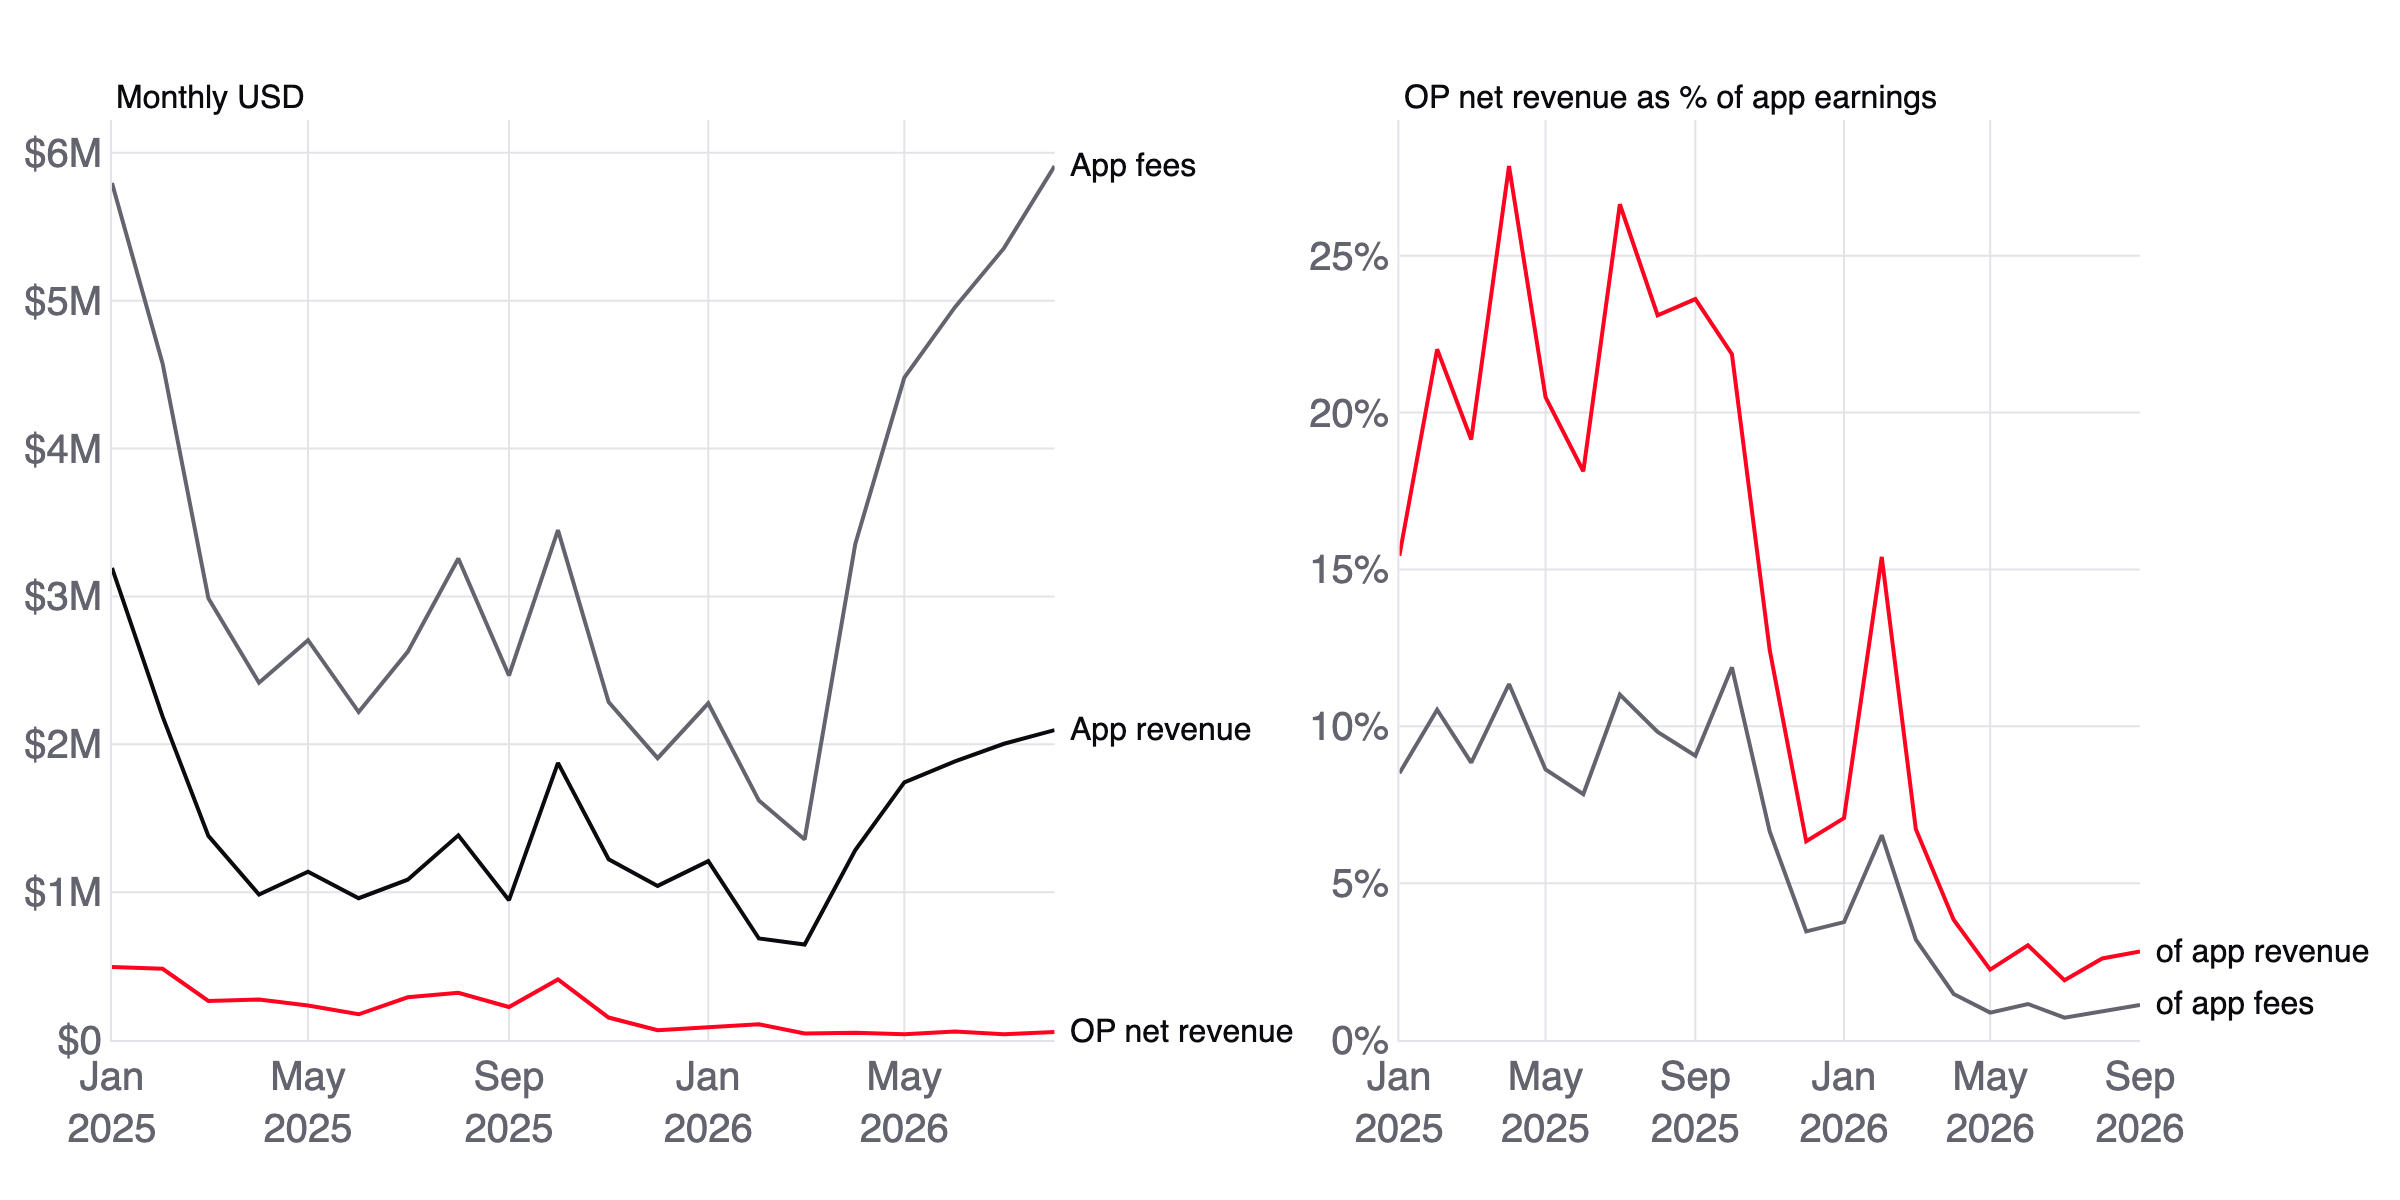

,month,full_month,app_fees_usd,app_revenue_usd,op_net_usd,take_of_app_fees,take_of_app_revenue
0,2025-01-01,True,5.795637e+06,3.192666e+06,492873.819086,0.085042,0.154377
1,2025-02-01,True,4.573917e+06,2.186940e+06,481538.886600,0.105279,0.220188
2,2025-03-01,True,2.987923e+06,1.380311e+06,264206.364892,0.088425,0.191411
3,2025-04-01,True,2.415953e+06,9.840951e+05,274169.710311,0.113483,0.278601
4,2025-05-01,True,2.703938e+06,1.137804e+06,233163.786048,0.086231,0.204924
5,2025-06-01,True,2.217976e+06,9.587063e+05,173812.352459,0.078365,0.181299
6,2025-07-01,True,2.625088e+06,1.084578e+06,288942.392522,0.110070,0.266410
7,2025-08-01,True,3.256770e+06,1.384314e+06,319813.394864,0.098200,0.231027
8,2025-09-01,True,2.464830e+06,9.456283e+05,223331.091597,0.090607,0.236172
9,2025-10-01,True,3.448673e+06,1.873834e+06,409660.142589,0.118788,0.218621


In [23]:
apps_monthly = con.sql("""
    with app as (
        select date_trunc('month', date)::date as month, sum(fee_usd) as app_fees_usd, sum(revenue_usd) as app_revenue_usd
        from app_fees
        group by month
    ), op as (
        select date_trunc('month', date)::date as month,
               count(*) = day(last_day(min(date))) as full_month,
               sum(net_fee_usd) as op_net_usd
        from pnl_daily
        group by month
    )
    select month, full_month, app_fees_usd, app_revenue_usd, op_net_usd,
           op_net_usd / app_fees_usd as take_of_app_fees,
           op_net_usd / app_revenue_usd as take_of_app_revenue
    from app join op using (month)
    order by month
""").df()


def rev_vs_apps(t: dict) -> go.Figure:
    fig = subplots(t, rows=1, cols=2, column_widths=[0.56, 0.44], horizontal_spacing=0.17,
                   subplot_titles=("Monthly USD", "OP net revenue as % of app earnings"))
    m, full = apps_monthly, apps_monthly[apps_monthly["full_month"]]
    series = (
        ("App fees", full["month"], full["app_fees_usd"], t["muted"], 1),
        ("App revenue", full["month"], full["app_revenue_usd"], t["ink"], 1),
        ("OP net revenue", full["month"], full["op_net_usd"], t["op"], 1),
        ("of app revenue", m["month"], m["take_of_app_revenue"], t["op"], 2),
        ("of app fees", m["month"], m["take_of_app_fees"], t["muted"], 2),
    )
    for name, x, y, color, col in series:
        fig.add_scatter(x=x, y=y, mode="lines", line=dict(color=color, width=2), showlegend=False, row=1, col=col)
        fig.add_annotation(x=x.iloc[-1], y=y.iloc[-1], text=name, xanchor="left", xshift=6, showarrow=False,
                           font=dict(size=16, color=t["ink"]), row=1, col=col)
    fig.update_layout(margin=dict(t=60, r=130, b=80))
    fig.update_yaxes(tickprefix="$", tickformat="~s", rangemode="tozero", row=1, col=1)
    fig.update_yaxes(tickformat=".0%", rangemode="tozero", row=1, col=2)
    fig.update_xaxes(dtick="M4", tickformat="%b<br>%Y")
    fig.update_xaxes(range=[full["month"].iloc[0], full["month"].iloc[-1]], col=1)
    fig.update_xaxes(range=[m["month"].iloc[0], m["month"].iloc[-1]], col=2)
    return fig


show(rev_vs_apps)
apps_monthly

## How do Base and Arbitrum compare with OP Mainnet? (growthepie, same TTM window, growthepie's own USD)

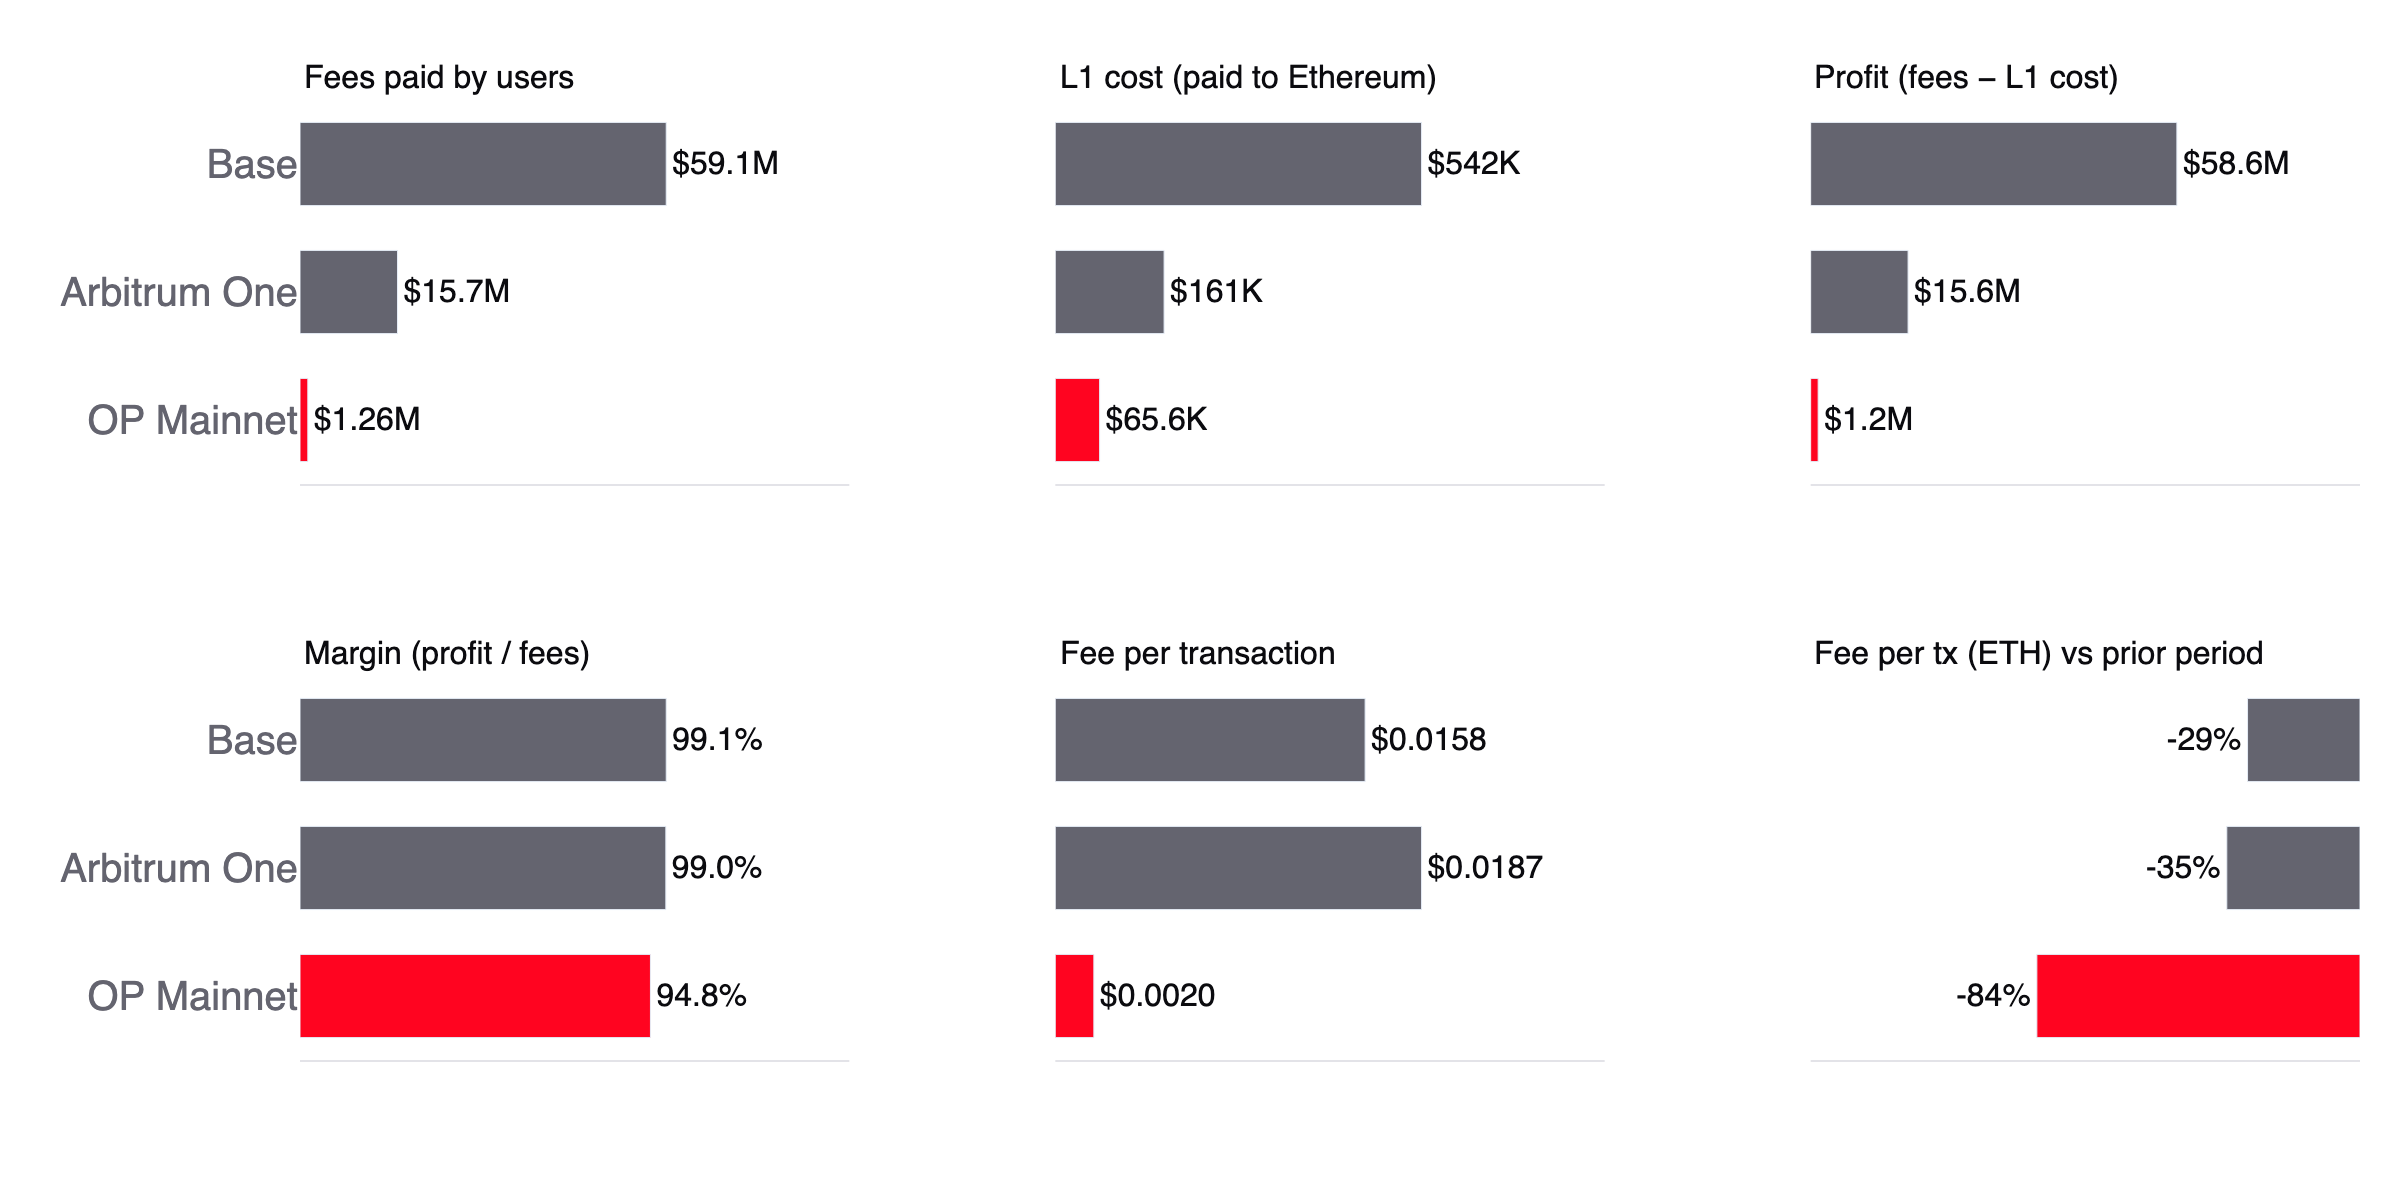

,origin_key,fees_usd,l1_cost_usd,profit_usd,profit_eth,txs,margin,fee_per_tx_usd,fee_per_tx_eth_change,profit_eth_vs_op,txs_vs_op,fee_per_tx_vs_op
0,optimism,1.263261e+06,65552.861698,1.197709e+06,407.599271,6.439543e+08,0.948108,0.001962,-0.840036,1.000000,1.000000,1.000000
1,arbitrum,1.574408e+07,160992.624153,1.558309e+07,5290.352609,8.440507e+08,0.989774,0.018653,-0.346320,12.979299,1.310731,9.508470
2,base,5.913984e+07,542056.207602,5.859778e+07,22747.606151,3.748295e+09,0.990834,0.015778,-0.292344,55.808751,5.820747,8.042817


In [24]:
peers = con.sql("""
    with d as (
        select origin_key, date, date >= '2025-09-16' as ttm, metric_key, value
        from gtp_metrics
        where origin_key in ('optimism', 'base', 'arbitrum') and date between '2025-01-01' and '2026-09-15'
    ), ttm as (
        select origin_key,
               sum(value) filter (where metric_key = 'fees_paid_usd') as fees_usd,
               sum(value) filter (where metric_key = 'rent_paid_usd') as l1_cost_usd,
               sum(value) filter (where metric_key = 'profit_usd') as profit_usd,
               sum(value) filter (where metric_key = 'profit_eth') as profit_eth,
               sum(value) filter (where metric_key = 'txcount') as txs
        from d
        where ttm
        group by origin_key
    ), fee_per_tx_eth as (  -- growthepie's OP fees are doubled on 2025-04-13/14, so those days are left out of the change
        select origin_key,
               sum(value) filter (where metric_key = 'fees_paid_eth' and ttm)
                   / sum(value) filter (where metric_key = 'txcount' and ttm) as ttm,
               sum(value) filter (where metric_key = 'fees_paid_eth' and not ttm)
                   / sum(value) filter (where metric_key = 'txcount' and not ttm) as prior
        from d
        where date not in ('2025-04-13', '2025-04-14')
        group by origin_key
    ), op as (select * from ttm where origin_key = 'optimism')
    select t.origin_key, t.fees_usd, t.l1_cost_usd, t.profit_usd, t.profit_eth, t.txs,
           t.profit_usd / t.fees_usd as margin,
           t.fees_usd / t.txs as fee_per_tx_usd,
           f.ttm / f.prior - 1 as fee_per_tx_eth_change,
           t.profit_eth / op.profit_eth as profit_eth_vs_op,
           t.txs / op.txs as txs_vs_op,
           (t.fees_usd / t.txs) / (op.fees_usd / op.txs) as fee_per_tx_vs_op
    from ttm t
    join fee_per_tx_eth f using (origin_key)
    cross join op
    order by t.profit_usd
""").df()
by_chain = peers.set_index("origin_key")

note = "gtp_metrics (growthepie USD), exact TTM window daily incl. 1-15 Sep 2026"
for chain, short in (("optimism", "op"), ("base", "base"), ("arbitrum", "arb")):
    numbers.record(f"rev_peer_{short}_fee_per_tx_change", by_chain.loc[chain, "fee_per_tx_eth_change"],
                   note="gtp_metrics fees_paid_eth / txcount, TTM vs prior, excl. 2025-04-13/14")
    if chain != "optimism":
        numbers.record(f"rev_peer_{short}_ttm_profit_usd", by_chain.loc[chain, "profit_usd"], note=note)
        numbers.record(f"rev_peer_{short}_fee_per_tx_usd", by_chain.loc[chain, "fee_per_tx_usd"], note=note + "; fees / txcount")
numbers.record("rev_peer_base_profit_multiple", by_chain.loc["base", "profit_eth_vs_op"], note="gtp_metrics TTM profit_eth Base / OP")
numbers.record("rev_peer_base_fee_per_tx_multiple", by_chain.loc["base", "fee_per_tx_vs_op"], note="gtp_metrics TTM fee per tx Base / OP")
numbers.record("rev_peer_base_txs_multiple", by_chain.loc["base", "txs_vs_op"], note="gtp_metrics txcount Base / OP, same exact TTM daily window")
pulled = (ROOT / "data" / "external" / "PULLED.txt").read_text().splitlines()
numbers.record("rev_peer_pulled_at", next(line.split()[2] for line in pulled if line.startswith("growthepie")),
               note="data/external/PULLED.txt, growthepie pulled_at_utc")

NAMES = {"optimism": "OP Mainnet", "base": "Base", "arbitrum": "Arbitrum One"}
PANELS = (
    ("fees_usd", "Fees paid by users", usd),
    ("l1_cost_usd", "L1 cost (paid to Ethereum)", usd),
    ("profit_usd", "Profit (fees − L1 cost)", usd),
    ("margin", "Margin (profit / fees)", lambda v: f"{v:.1%}"),
    ("fee_per_tx_usd", "Fee per transaction", lambda v: f"${v:.4f}"),
    ("fee_per_tx_eth_change", "Fee per tx (ETH) vs prior period", lambda v: f"{v:+.0%}"),
)


def rev_peers(t: dict) -> go.Figure:
    fig = subplots(t, rows=2, cols=3, vertical_spacing=0.2, horizontal_spacing=0.1, subplot_titles=[title for _, title, _ in PANELS])
    names = [NAMES[k] for k in peers["origin_key"]]
    colors = [t["op"] if k == "optimism" else t["muted"] for k in peers["origin_key"]]
    for i, (col, _, fmt) in enumerate(PANELS):
        values = peers[col].tolist()
        lo, hi = min(0, *values), max(0, *values)
        fig.add_bar(x=values, y=names, orientation="h", marker=dict(color=colors), text=[fmt(v) for v in values],
                    textposition="outside", textfont=dict(color=t["ink"], size=16), cliponaxis=False,
                    row=i // 3 + 1, col=i % 3 + 1)
        fig.update_xaxes(range=[lo * 1.7, hi * 1.5], row=i // 3 + 1, col=i % 3 + 1)
    fig.update_xaxes(showticklabels=False, showgrid=False)
    fig.update_yaxes(showgrid=False, showline=False)
    fig.update_yaxes(showticklabels=False, col=2)
    fig.update_yaxes(showticklabels=False, col=3)
    fig.update_layout(showlegend=False, bargap=0.35, margin=dict(l=150, t=50, b=70))
    return fig


show(rev_peers)
peers